# Data Preparation


In [1]:
!pip install -q ucimlrepo
!pip install -q torch-geometric
!pip install -q pandas numpy matplotlib seaborn scikit-learn

In [2]:
import requests
import zipfile
import os

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00501/PRSA2017_Data_20130301-20170228.zip"

zip_path = "/content/beijing_air_quality.zip"

response = requests.get(url, timeout=60)

print("Status:", response.status_code)
print("Ukuran file:", len(response.content), "bytes")

response.raise_for_status()

with open(zip_path, "wb") as f:
    f.write(response.content)

print("Dataset berhasil diunduh!")

Status: 200
Ukuran file: 7959991 bytes
Dataset berhasil diunduh!


In [3]:
extract_path = "/content/beijing_air_quality"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak!")

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

Dataset berhasil diekstrak!
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Wanliu_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Gucheng_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Shunyi_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Tiantan_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Wanshouxigong_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Dongsi_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Guanyuan_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Aotizhongxin_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Huairou_20130301-20170228.csv
/content/beijing_air_quality/PRSA_Data_20130301-20170228/PRSA_Data_Changping_20130301-2017

In [4]:
import glob
import pandas as pd

csv_files = glob.glob(
    extract_path + "/**/PRSA_Data_*.csv",
    recursive=True
)

print("Jumlah file CSV:", len(csv_files))

dataframes = []

for file in csv_files:
    temp_df = pd.read_csv(file)
    dataframes.append(temp_df)

df = pd.concat(dataframes, ignore_index=True)

df["datetime"] = pd.to_datetime(
    df[["year", "month", "day", "hour"]]
)

df = df.sort_values(
    ["datetime", "station"]
).reset_index(drop=True)

print("Ukuran dataset:", df.shape)
display(df.head())

Jumlah file CSV: 12
Ukuran dataset: (420768, 19)


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01
1,1,2013,3,1,0,3.0,6.0,13.0,7.0,300.0,85.0,-2.3,1020.8,-19.7,0.0,E,0.5,Changping,2013-03-01
2,1,2013,3,1,0,4.0,4.0,3.0,NaN,200.0,82.0,-2.3,1020.8,-19.7,0.0,E,0.5,Dingling,2013-03-01
3,1,2013,3,1,0,9.0,9.0,3.0,17.0,300.0,89.0,-0.5,1024.5,-21.4,0.0,NNW,5.7,Dongsi,2013-03-01
4,1,2013,3,1,0,4.0,4.0,14.0,20.0,300.0,69.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Guanyuan,2013-03-01


In [5]:
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah stasiun:", df["station"].nunique())
print("Nama stasiun:", df["station"].unique())

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistik PM2.5:")
print(df["PM2.5"].describe())

Jumlah baris dan kolom: (420768, 19)
Jumlah stasiun: 12
Nama stasiun: ['Aotizhongxin' 'Changping' 'Dingling' 'Dongsi' 'Guanyuan' 'Gucheng'
 'Huairou' 'Nongzhanguan' 'Shunyi' 'Tiantan' 'Wanliu' 'Wanshouxigong']

Missing values:
No              0
year            0
month           0
day             0
hour            0
PM2.5        8739
PM10         6449
SO2          9021
NO2         12116
CO          20701
O3          13277
TEMP          398
PRES          393
DEWP          403
RAIN          390
wd           1822
WSPM          318
station         0
datetime        0
dtype: int64

Statistik PM2.5:
count    412029.000000
mean         79.793428
std          80.822391
min           2.000000
25%          20.000000
50%          55.000000
75%         111.000000
max         999.000000
Name: PM2.5, dtype: float64


In [6]:
# Jumlah nilai PM2.5 yang mencapai 999
print("Jumlah PM2.5 = 999:",
      (df["PM2.5"] == 999).sum())

# Jumlah nilai PM2.5 di atas 500
print("Jumlah PM2.5 > 500:",
      (df["PM2.5"] > 500).sum())

# Distribusi nilai PM2.5 = 999 berdasarkan stasiun
print("\nPM2.5 = 999 berdasarkan stasiun:")
print(
    df[df["PM2.5"] == 999]
    .groupby("station")
    .size()
)

# Lihat contoh data dengan PM2.5 = 999
display(
    df[df["PM2.5"] == 999][
        ["datetime", "station", "PM2.5", "PM10", "SO2", "NO2", "CO"]
    ].head(20)
)

Jumlah PM2.5 = 999: 1
Jumlah PM2.5 > 500: 933

PM2.5 = 999 berdasarkan stasiun:
station
Wanshouxigong    1
dtype: int64


,datetime,station,PM2.5,PM10,SO2,NO2,CO
309347,2016-02-08 02:00:00,Wanshouxigong,999.0,NaN,299.0,82.0,2700.0


In [7]:
missing_station = (
    df.groupby("station")
    .agg(
        total_data=("PM2.5", "size"),
        missing_PM25=("PM2.5", lambda x: x.isnull().sum()),
        missing_PM10=("PM10", lambda x: x.isnull().sum()),
        missing_CO=("CO", lambda x: x.isnull().sum())
    )
)

missing_station["PM25_missing_percent"] = (
    missing_station["missing_PM25"] /
    missing_station["total_data"] * 100
)

display(missing_station)

,total_data,missing_PM25,missing_PM10,missing_CO,PM25_missing_percent
station,,,,,
Aotizhongxin,35064,925,718,1776,2.638033
Changping,35064,774,582,1521,2.207392
Dingling,35064,779,656,2012,2.221652
Dongsi,35064,750,553,3197,2.138946
Guanyuan,35064,616,429,1753,1.756788
Gucheng,35064,646,381,1401,1.842345
Huairou,35064,953,777,1422,2.717887
Nongzhanguan,35064,628,440,1206,1.791011
Shunyi,35064,913,548,2178,2.603810


In [8]:
# Duplikasi berdasarkan stasiun dan waktu
duplicate_count = df.duplicated(
    subset=["station", "datetime"]
).sum()

print("Jumlah data duplikat:", duplicate_count)

# Rentang waktu dataset
print("Tanggal awal:", df["datetime"].min())
print("Tanggal akhir:", df["datetime"].max())

# Jumlah data setiap stasiun
print("\nJumlah data per stasiun:")
print(df.groupby("station").size())

Jumlah data duplikat: 0
Tanggal awal: 2013-03-01 00:00:00
Tanggal akhir: 2017-02-28 23:00:00

Jumlah data per stasiun:
station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
dtype: int64


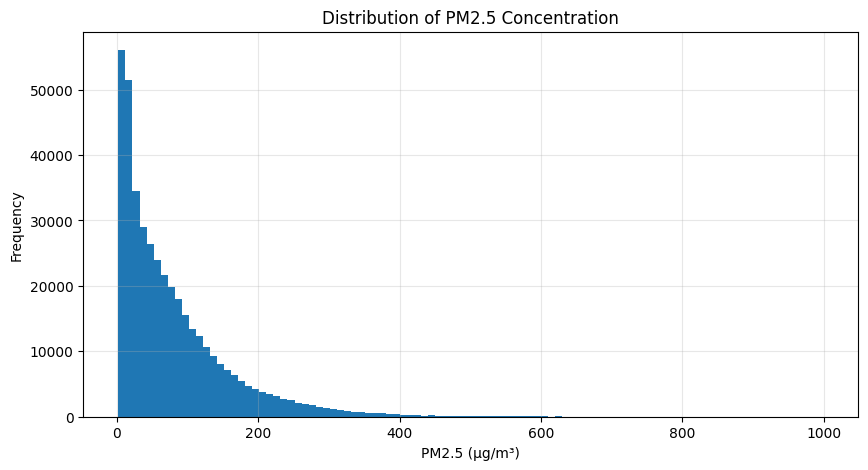

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

df["PM2.5"].dropna().hist(bins=100)

plt.title("Distribution of PM2.5 Concentration")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

# Implementation Algorithm

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler

# Pastikan data terurut
df = df.copy()

df["datetime"] = pd.to_datetime(df["datetime"])

df = df.sort_values(
    ["datetime", "station"]
).reset_index(drop=True)

# Periksa duplikasi
print("Duplikasi:", df.duplicated(
    subset=["datetime", "station"]
).sum())

# Hilangkan duplikasi jika ada
df = df.drop_duplicates(
    subset=["datetime", "station"]
).reset_index(drop=True)

# Urutan stasiun
stations = sorted(df["station"].unique())

print("Jumlah stasiun:", len(stations))
print("Daftar stasiun:", stations)

Duplikasi: 0
Jumlah stasiun: 12
Daftar stasiun: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


In [11]:
wind_direction = {
    "N": 0,
    "NNE": 22.5,
    "NE": 45,
    "ENE": 67.5,
    "E": 90,
    "ESE": 112.5,
    "SE": 135,
    "SSE": 157.5,
    "S": 180,
    "SSW": 202.5,
    "SW": 225,
    "WSW": 247.5,
    "W": 270,
    "WNW": 292.5,
    "NW": 315,
    "NNW": 337.5
}

df["wd_degree"] = df["wd"].map(wind_direction)

df["wd_sin"] = np.sin(
    np.deg2rad(df["wd_degree"])
)

df["wd_cos"] = np.cos(
    np.deg2rad(df["wd_degree"])
)

print(df[["wd", "wd_degree", "wd_sin", "wd_cos"]].head())

    wd  wd_degree    wd_sin        wd_cos
0  NNW      337.5 -0.382683  9.238795e-01
1    E       90.0  1.000000  6.123234e-17
2    E       90.0  1.000000  6.123234e-17
3  NNW      337.5 -0.382683  9.238795e-01
4  NNW      337.5 -0.382683  9.238795e-01


In [12]:
feature_columns = [
    "PM2.5",
    "PM10",
    "SO2",
    "NO2",
    "CO",
    "O3",
    "TEMP",
    "PRES",
    "DEWP",
    "RAIN",
    "WSPM",
    "wd_sin",
    "wd_cos"
]

target_column = "PM2.5"

print("Jumlah fitur:", len(feature_columns))
print("Target:", target_column)

Jumlah fitur: 13
Target: PM2.5


In [13]:
# Membuat indeks waktu
timestamps = pd.date_range(
    start=df["datetime"].min(),
    end=df["datetime"].max(),
    freq="h"
)

# Membentuk matriks fitur
feature_matrices = []

for col in feature_columns:

    pivot = df.pivot(
        index="datetime",
        columns="station",
        values=col
    )

    pivot = pivot.reindex(
        index=timestamps,
        columns=stations
    )

    feature_matrices.append(
        pivot.to_numpy(dtype=float)
    )

# Bentuk: waktu x stasiun x fitur
X_raw = np.stack(
    feature_matrices,
    axis=-1
)

# Matriks target PM2.5
y_pivot = df.pivot(
    index="datetime",
    columns="station",
    values="PM2.5"
)

y_pivot = y_pivot.reindex(
    index=timestamps,
    columns=stations
)

y_raw = y_pivot.to_numpy(dtype=float)

print("Bentuk X:", X_raw.shape)
print("Bentuk y:", y_raw.shape)
print("Jumlah waktu:", len(timestamps))
print("Jumlah stasiun:", len(stations))
print("Jumlah fitur:", len(feature_columns))

Bentuk X: (35064, 12, 13)
Bentuk y: (35064, 12)
Jumlah waktu: 35064
Jumlah stasiun: 12
Jumlah fitur: 13


In [14]:
n_time = len(timestamps)

train_end = int(n_time * 0.70)
val_end = int(n_time * 0.85)

print("Total waktu:", n_time)
print("Training:", train_end)
print("Validation:", val_end - train_end)
print("Testing:", n_time - val_end)

print("\nPeriode training:")
print(timestamps[0], "sampai", timestamps[train_end - 1])

print("\nPeriode validation:")
print(timestamps[train_end], "sampai", timestamps[val_end - 1])

print("\nPeriode testing:")
print(timestamps[val_end], "sampai", timestamps[-1])

Total waktu: 35064
Training: 24544
Validation: 5260
Testing: 5260

Periode training:
2013-03-01 00:00:00 sampai 2015-12-18 15:00:00

Periode validation:
2015-12-18 16:00:00 sampai 2016-07-24 19:00:00

Periode testing:
2016-07-24 20:00:00 sampai 2017-02-28 23:00:00


In [15]:
# Median training per stasiun dan fitur
with np.errstate(all="ignore"):
    station_medians = np.nanmedian(
        X_raw[:train_end],
        axis=0
    )

# Fallback jika suatu fitur pada stasiun seluruhnya kosong
global_medians = np.nanmedian(
    X_raw[:train_end].reshape(-1, len(feature_columns)),
    axis=0
)

for station_idx in range(len(stations)):
    for feature_idx in range(len(feature_columns)):

        median_value = station_medians[
            station_idx, feature_idx
        ]

        if not np.isfinite(median_value):
            median_value = global_medians[feature_idx]

        if not np.isfinite(median_value):
            median_value = 0.0

        missing_idx = np.isnan(
            X_raw[:, station_idx, feature_idx]
        )

        X_raw[missing_idx, station_idx, feature_idx] = median_value

# Normalisasi fitur
scaler_X = StandardScaler()

X_train_flat = X_raw[:train_end].reshape(
    -1, len(feature_columns)
)

scaler_X.fit(X_train_flat)

X = scaler_X.transform(
    X_raw.reshape(-1, len(feature_columns))
).reshape(X_raw.shape)

# Normalisasi target berdasarkan target training yang tersedia
scaler_y = StandardScaler()

train_targets = y_raw[1:train_end]
valid_targets = train_targets[
    np.isfinite(train_targets)
].reshape(-1, 1)

scaler_y.fit(valid_targets)

y = np.full(y_raw.shape, np.nan, dtype=float)

valid_target_mask = np.isfinite(y_raw)

y[valid_target_mask] = scaler_y.transform(
    y_raw[valid_target_mask].reshape(-1, 1)
).ravel()

print("Preprocessing selesai!")
print("X:", X.shape)
print("y:", y.shape)
print("Missing fitur:", np.isnan(X).sum())
print("Missing target:", np.isnan(y).sum())

Preprocessing selesai!
X: (35064, 12, 13)
y: (35064, 12)
Missing fitur: 0
Missing target: 8739


## Membangun Graph

In [16]:
import numpy as np
import pandas as pd

coordinates = {
    "Aotizhongxin": (39.982, 116.397),
    "Changping": (40.217, 116.230),
    "Dingling": (40.292, 116.220),
    "Dongsi": (39.929, 116.417),
    "Guanyuan": (39.929, 116.339),
    "Gucheng": (39.914, 116.184),
    "Huairou": (40.328, 116.628),
    "Nongzhanguan": (39.937, 116.461),
    "Shunyi": (40.127, 116.655),
    "Tiantan": (39.886, 116.407),
    "Wanliu": (39.987, 116.287),
    "Wanshouxigong": (39.878, 116.352)
}

# Sesuaikan urutan dengan stations
coords = np.array([
    coordinates[station] for station in stations
])

print("Urutan stasiun:")
for i, station in enumerate(stations):
    print(i, station, coords[i])

Urutan stasiun:
0 Aotizhongxin [ 39.982 116.397]
1 Changping [ 40.217 116.23 ]
2 Dingling [ 40.292 116.22 ]
3 Dongsi [ 39.929 116.417]
4 Guanyuan [ 39.929 116.339]
5 Gucheng [ 39.914 116.184]
6 Huairou [ 40.328 116.628]
7 Nongzhanguan [ 39.937 116.461]
8 Shunyi [ 40.127 116.655]
9 Tiantan [ 39.886 116.407]
10 Wanliu [ 39.987 116.287]
11 Wanshouxigong [ 39.878 116.352]


In [17]:
from scipy.spatial.distance import cdist

def haversine_matrix(coords):
    lat = np.radians(coords[:, 0])
    lon = np.radians(coords[:, 1])

    lat1 = lat[:, None]
    lat2 = lat[None, :]

    lon1 = lon[:, None]
    lon2 = lon[None, :]

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 6371 * 2 * np.arcsin(
        np.sqrt(np.clip(a, 0, 1))
    )

distance_matrix = haversine_matrix(coords)

distance_df = pd.DataFrame(
    distance_matrix,
    index=stations,
    columns=stations
)

display(distance_df.round(2))

,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
Aotizhongxin,0.00,29.74,37.61,6.13,7.69,19.67,43.19,7.40,27.24,10.71,9.39,12.18
Changping,29.74,0.00,8.38,35.76,33.34,33.92,35.95,36.82,37.47,39.77,26.03,39.10
Dingling,37.61,8.38,0.00,43.70,41.61,42.14,34.83,44.48,41.24,47.87,34.39,47.38
Dongsi,6.13,35.76,43.70,0.00,6.65,19.94,47.86,3.86,29.92,4.86,12.82,7.93
Guanyuan,7.69,33.34,41.61,6.65,0.00,13.32,50.72,10.44,34.77,7.52,7.83,5.78
Gucheng,19.67,33.92,42.14,19.94,13.32,0.00,59.54,23.76,46.58,19.28,11.96,14.88
Huairou,43.19,35.95,34.83,47.86,50.72,59.54,0.00,45.74,22.47,52.62,47.72,55.27
Nongzhanguan,7.40,36.82,44.48,3.86,10.44,23.76,45.74,0.00,26.82,7.31,15.84,11.38
Shunyi,27.24,37.47,41.24,29.92,34.77,46.58,22.47,26.82,0.00,34.12,34.98,37.85
Tiantan,10.71,39.77,47.87,4.86,7.52,19.28,52.62,7.31,34.12,0.00,15.19,4.78


In [18]:
num_stations = len(stations)
k = 3

adjacency = np.zeros(
    (num_stations, num_stations)
)

for i in range(num_stations):

    nearest = np.argsort(
        distance_matrix[i]
    )[1:k+1]

    for j in nearest:
        adjacency[i, j] = 1
        adjacency[j, i] = 1

print("Adjacency Matrix:")
display(pd.DataFrame(
    adjacency,
    index=stations,
    columns=stations
))

Adjacency Matrix:


,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
Aotizhongxin,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0
Changping,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
Dingling,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
Dongsi,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
Guanyuan,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,1.0
Gucheng,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
Huairou,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
Nongzhanguan,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0
Shunyi,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
Tiantan,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [19]:
# Gaussian distance weighting
nonzero_distances = distance_matrix[
    distance_matrix > 0
]

sigma = np.median(nonzero_distances)

adjacency_weighted = np.exp(
    -(distance_matrix ** 2) / (2 * sigma ** 2)
) * adjacency

# Self-loop
np.fill_diagonal(adjacency_weighted, 1.0)

print("Weighted adjacency matrix:")
display(pd.DataFrame(
    adjacency_weighted,
    index=stations,
    columns=stations
).round(3))

Weighted adjacency matrix:


,Aotizhongxin,Changping,Dingling,Dongsi,Guanyuan,Gucheng,Huairou,Nongzhanguan,Shunyi,Tiantan,Wanliu,Wanshouxigong
Aotizhongxin,1.000,0.580,0.000,0.977,0.964,0.000,0.000,0.967,0.633,0.000,0.947,0.000
Changping,0.580,1.000,0.958,0.000,0.000,0.000,0.451,0.000,0.000,0.000,0.659,0.000
Dingling,0.000,0.958,1.000,0.000,0.000,0.000,0.474,0.000,0.000,0.000,0.483,0.000
Dongsi,0.977,0.000,0.000,1.000,0.973,0.000,0.000,0.991,0.000,0.986,0.000,0.962
Guanyuan,0.964,0.000,0.000,0.973,1.000,0.896,0.000,0.000,0.000,0.966,0.963,0.980
Gucheng,0.000,0.000,0.000,0.000,0.896,1.000,0.000,0.000,0.000,0.000,0.916,0.873
Huairou,0.000,0.451,0.474,0.000,0.000,0.000,1.000,0.000,0.733,0.000,0.000,0.000
Nongzhanguan,0.967,0.000,0.000,0.991,0.000,0.000,0.000,1.000,0.642,0.968,0.000,0.000
Shunyi,0.633,0.000,0.000,0.000,0.000,0.000,0.733,0.642,1.000,0.000,0.000,0.000
Tiantan,0.000,0.000,0.000,0.986,0.966,0.000,0.000,0.968,0.000,1.000,0.000,0.986


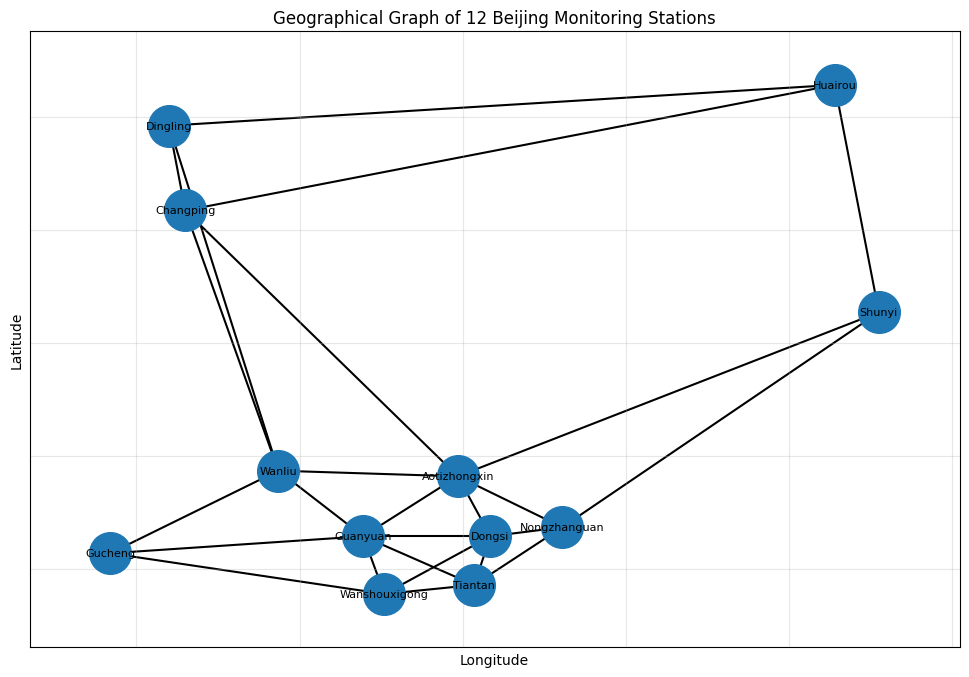

In [20]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.Graph()

for i, station in enumerate(stations):
    G.add_node(
        station,
        pos=(coords[i, 1], coords[i, 0])
    )

for i in range(num_stations):
    for j in range(i + 1, num_stations):

        if adjacency[i, j] == 1:
            G.add_edge(
                stations[i],
                stations[j],
                weight=adjacency_weighted[i, j]
            )

pos = nx.get_node_attributes(G, "pos")

plt.figure(figsize=(12, 8))

nx.draw_networkx(
    G,
    pos,
    with_labels=True,
    node_size=900,
    font_size=8,
    width=1.5
)

plt.title("Geographical Graph of 12 Beijing Monitoring Stations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.grid(alpha=0.3)
plt.show()

In [21]:
import torch

edge_index = torch.tensor(
    np.array(np.nonzero(adjacency)),
    dtype=torch.long
)

edge_weight = torch.tensor(
    adjacency_weighted[
        adjacency > 0
    ],
    dtype=torch.float32
)

print("Edge index shape:", edge_index.shape)
print("Edge weight shape:", edge_weight.shape)
print("Jumlah edge:", edge_index.shape[1])

Edge index shape: torch.Size([2, 50])
Edge weight shape: torch.Size([50])
Jumlah edge: 50


## Menyiapkan data untuk model

In [22]:
# Input waktu t
X_model = X[:-1]

# Target satu jam setelahnya
y_model = y[1:]

# Mask untuk label yang tersedia
target_mask = np.isfinite(y_model)

print("X model:", X_model.shape)
print("Y model:", y_model.shape)
print("Target tersedia:", target_mask.sum())

X model: (35063, 12, 13)
Y model: (35063, 12)
Target tersedia: 412017


In [23]:
n_samples = len(X_model)

train_end = int(n_samples * 0.70)
val_end = int(n_samples * 0.85)

X_train = X_model[:train_end]
X_val = X_model[train_end:val_end]
X_test = X_model[val_end:]

y_train = y_model[:train_end]
y_val = y_model[train_end:val_end]
y_test = y_model[val_end:]

mask_train = target_mask[:train_end]
mask_val = target_mask[train_end:val_end]
mask_test = target_mask[val_end:]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

Training: (24544, 12, 13) (24544, 12)
Validation: (5259, 12, 13) (5259, 12)
Testing: (5260, 12, 13) (5260, 12)


# Implementasi Algoritma GNN

In [24]:
!pip install -q torch-geometric

In [25]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch_geometric.nn import SAGEConv, GCNConv, GATConv
from torch.utils.data import TensorDataset, DataLoader

import copy
import random
import numpy as np

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cpu


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [26]:
def prepare_tensors(X_data, y_data, mask_data):

    X_tensor = torch.tensor(
        X_data, dtype=torch.float32
    )

    y_clean = np.nan_to_num(
        y_data, nan=0.0
    )

    y_tensor = torch.tensor(
        y_clean, dtype=torch.float32
    )

    mask_tensor = torch.tensor(
        mask_data, dtype=torch.bool
    )

    return X_tensor, y_tensor, mask_tensor


X_train_t, y_train_t, mask_train_t = prepare_tensors(
    X_train, y_train, mask_train
)

X_val_t, y_val_t, mask_val_t = prepare_tensors(
    X_val, y_val, mask_val
)

X_test_t, y_test_t, mask_test_t = prepare_tensors(
    X_test, y_test, mask_test
)

train_dataset = TensorDataset(
    X_train_t, y_train_t, mask_train_t
)

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

print("Jumlah batch training:", len(train_loader))

Jumlah batch training: 384


In [27]:
edge_index_base = torch.tensor(
    np.array(np.nonzero(adjacency)),
    dtype=torch.long
)

def create_batched_edge_index(batch_size):

    edges = []

    for b in range(batch_size):

        offset = b * num_stations

        edges.append(
            edge_index_base + offset
        )

    return torch.cat(edges, dim=1).to(device)

In [28]:
class GraphSAGEModel(nn.Module):

    def __init__(self, in_channels, hidden_channels=32):
        super().__init__()

        self.conv1 = SAGEConv(
            in_channels, hidden_channels
        )

        self.conv2 = SAGEConv(
            hidden_channels, hidden_channels
        )

        self.output = nn.Linear(
            hidden_channels, 1
        )

    def forward(self, x, edge_index):

        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.2, training=self.training)

        x = F.relu(self.conv2(x, edge_index))

        return self.output(x).squeeze(-1)


class GCNModel(nn.Module):

    def __init__(self, in_channels, hidden_channels=32):
        super().__init__()

        self.conv1 = GCNConv(
            in_channels, hidden_channels
        )

        self.conv2 = GCNConv(
            hidden_channels, hidden_channels
        )

        self.output = nn.Linear(
            hidden_channels, 1
        )

    def forward(self, x, edge_index):

        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.2, training=self.training)

        x = F.relu(self.conv2(x, edge_index))

        return self.output(x).squeeze(-1)


class GATModel(nn.Module):

    def __init__(self, in_channels, hidden_channels=32):
        super().__init__()

        self.conv1 = GATConv(
            in_channels,
            hidden_channels // 4,
            heads=4,
            concat=True
        )

        self.conv2 = GATConv(
            hidden_channels,
            hidden_channels,
            heads=1,
            concat=False
        )

        self.output = nn.Linear(
            hidden_channels, 1
        )

    def forward(self, x, edge_index):

        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.2, training=self.training)

        x = F.elu(self.conv2(x, edge_index))

        return self.output(x).squeeze(-1)

In [29]:
def masked_mse(pred, target, mask):

    if mask.sum() == 0:
        return None

    return ((pred[mask] - target[mask]) ** 2).mean()


def evaluate_loss(model, X_data, y_data, mask_data):

    model.eval()

    total_loss = 0
    total_count = 0

    with torch.no_grad():

        for start in range(0, len(X_data), 64):

            end = start + 64

            xb = X_data[start:end].to(device)
            yb = y_data[start:end].to(device)
            mb = mask_data[start:end].to(device)

            batch_size = len(xb)

            edge_index = create_batched_edge_index(
                batch_size
            )

            xb = xb.reshape(
                batch_size * num_stations,
                -1
            )

            pred = model(xb, edge_index).reshape(
                batch_size, num_stations
            )

            loss = masked_mse(pred, yb, mb)

            if loss is not None:
                count = mb.sum().item()
                total_loss += loss.item() * count
                total_count += count

    return total_loss / total_count


def train_model(model, epochs=50, patience=10):

    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-5
    )

    best_val_loss = float("inf")
    best_state = None
    wait = 0

    history = {
        "train_loss": [],
        "val_loss": []
    }

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        total_count = 0

        for xb, yb, mb in train_loader:

            xb = xb.to(device)
            yb = yb.to(device)
            mb = mb.to(device)

            batch_size = len(xb)

            edge_index = create_batched_edge_index(
                batch_size
            )

            xb = xb.reshape(
                batch_size * num_stations,
                -1
            )

            optimizer.zero_grad()

            pred = model(
                xb, edge_index
            ).reshape(batch_size, num_stations)

            loss = masked_mse(pred, yb, mb)

            if loss is None:
                continue

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            optimizer.step()

            count = mb.sum().item()

            total_loss += loss.item() * count
            total_count += count

        train_loss = total_loss / total_count

        val_loss = evaluate_loss(
            model,
            X_val_t,
            y_val_t,
            mask_val_t
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        print(
            f"Epoch {epoch+1:02d} | "
            f"Train Loss: {train_loss:.5f} | "
            f"Val Loss: {val_loss:.5f}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_state = copy.deepcopy(
                model.state_dict()
            )

            wait = 0

        else:

            wait += 1

        if wait >= patience:
            print("Early stopping!")
            break

    model.load_state_dict(best_state)

    return model, history

In [30]:
models = {
    "GraphSAGE": GraphSAGEModel(
        in_channels=len(feature_columns)
    ),

    "GCN": GCNModel(
        in_channels=len(feature_columns)
    ),

    "GAT": GATModel(
        in_channels=len(feature_columns)
    )
}

trained_models = {}
histories = {}

for name, model in models.items():

    print("\n" + "="*50)
    print("TRAINING:", name)
    print("="*50)

    trained_model, history = train_model(
        model,
        epochs=50,
        patience=10
    )

    trained_models[name] = trained_model
    histories[name] = history


TRAINING: GraphSAGE
Epoch 01 | Train Loss: 0.14228 | Val Loss: 0.08370
Epoch 02 | Train Loss: 0.08013 | Val Loss: 0.08022
Epoch 03 | Train Loss: 0.07382 | Val Loss: 0.07198
Epoch 04 | Train Loss: 0.07035 | Val Loss: 0.07102
Epoch 05 | Train Loss: 0.06846 | Val Loss: 0.07087
Epoch 06 | Train Loss: 0.06738 | Val Loss: 0.07625
Epoch 07 | Train Loss: 0.06592 | Val Loss: 0.07164
Epoch 08 | Train Loss: 0.06495 | Val Loss: 0.07878
Epoch 09 | Train Loss: 0.06406 | Val Loss: 0.08559
Epoch 10 | Train Loss: 0.06326 | Val Loss: 0.08646
Epoch 11 | Train Loss: 0.06259 | Val Loss: 0.08040
Epoch 12 | Train Loss: 0.06252 | Val Loss: 0.08321
Epoch 13 | Train Loss: 0.06182 | Val Loss: 0.08153
Epoch 14 | Train Loss: 0.06111 | Val Loss: 0.09575
Epoch 15 | Train Loss: 0.06102 | Val Loss: 0.08825
Early stopping!

TRAINING: GCN
Epoch 01 | Train Loss: 0.17382 | Val Loss: 0.11106
Epoch 02 | Train Loss: 0.10635 | Val Loss: 0.10789
Epoch 03 | Train Loss: 0.10286 | Val Loss: 0.10723
Epoch 04 | Train Loss: 0.10145

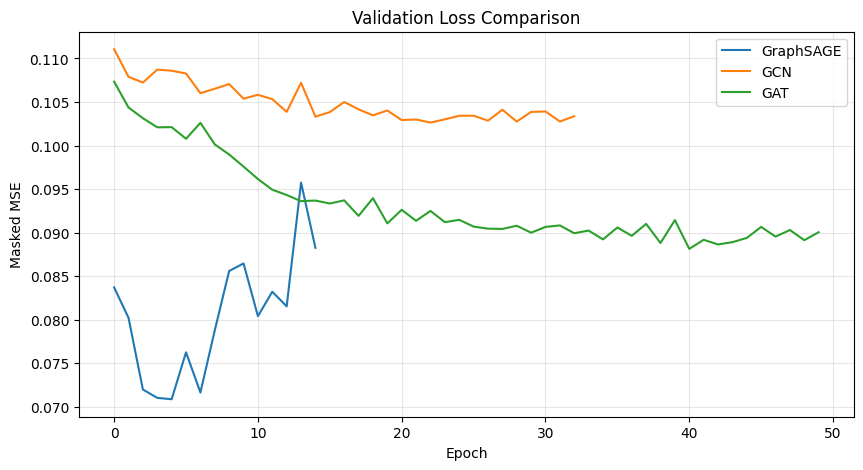

In [31]:
plt.figure(figsize=(10, 5))

for name, history in histories.items():

    plt.plot(
        history["val_loss"],
        label=name
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Masked MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Evaluasi Model

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def get_predictions(model, X_data):

    model.eval()
    predictions = []

    with torch.no_grad():

        for start in range(0, len(X_data), 64):

            xb = X_data[start:start+64].to(device)
            batch_size = len(xb)

            edge_index = create_batched_edge_index(batch_size)

            xb = xb.reshape(
                batch_size * num_stations,
                -1
            )

            pred = model(
                xb, edge_index
            ).reshape(batch_size, num_stations)

            predictions.append(
                pred.cpu().numpy()
            )

    return np.concatenate(predictions, axis=0)

In [33]:
results = []
predictions_dict = {}

for name, model in trained_models.items():

    # Prediksi dalam skala normalisasi
    pred_scaled = get_predictions(
        model, X_test_t
    )

    # Kembalikan ke skala PM2.5 asli
    pred_original = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).reshape(pred_scaled.shape)

    actual_original = scaler_y.inverse_transform(
        y_test_t.numpy().reshape(-1, 1)
    ).reshape(y_test_t.shape)

    # Hanya gunakan target yang tersedia
    mask = mask_test_t.numpy()

    y_true = actual_original[mask]
    y_pred = pred_original[mask]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    results.append({
        "Algorithm": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    predictions_dict[name] = pred_original

results_df = pd.DataFrame(results)

display(
    results_df.round(4)
)

,Algorithm,MAE,RMSE,R2
0,GraphSAGE,11.2453,20.8470,0.9494
1,GCN,14.7327,26.3774,0.9190
2,GAT,12.7531,23.9496,0.9332


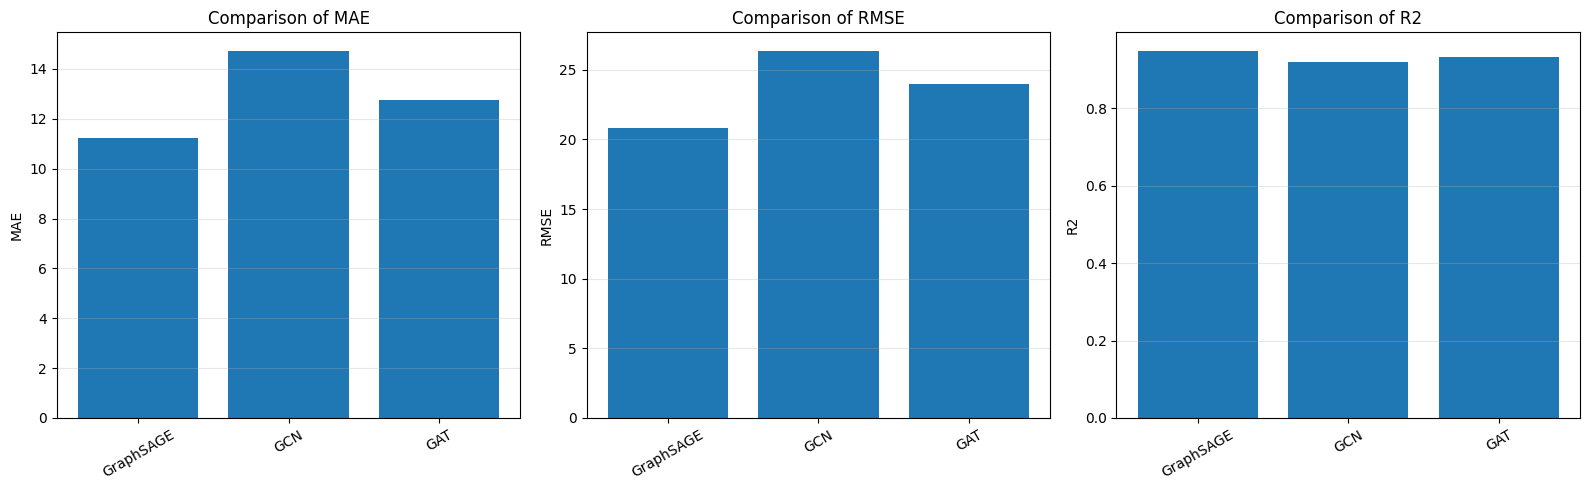

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["MAE", "RMSE", "R2"]

for ax, metric in zip(axes, metrics):

    ax.bar(
        results_df["Algorithm"],
        results_df[metric]
    )

    ax.set_title(f"Comparison of {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [35]:
best_mae = results_df.loc[
    results_df["MAE"].idxmin()
]

best_rmse = results_df.loc[
    results_df["RMSE"].idxmin()
]

best_r2 = results_df.loc[
    results_df["R2"].idxmax()
]

print("Model terbaik berdasarkan MAE:")
print(best_mae)

print("\nModel terbaik berdasarkan RMSE:")
print(best_rmse)

print("\nModel terbaik berdasarkan R2:")
print(best_r2)

Model terbaik berdasarkan MAE:
Algorithm    GraphSAGE
MAE          11.245344
RMSE         20.847029
R2            0.949398
Name: 0, dtype: object

Model terbaik berdasarkan RMSE:
Algorithm    GraphSAGE
MAE          11.245344
RMSE         20.847029
R2            0.949398
Name: 0, dtype: object

Model terbaik berdasarkan R2:
Algorithm    GraphSAGE
MAE          11.245344
RMSE         20.847029
R2            0.949398
Name: 0, dtype: object


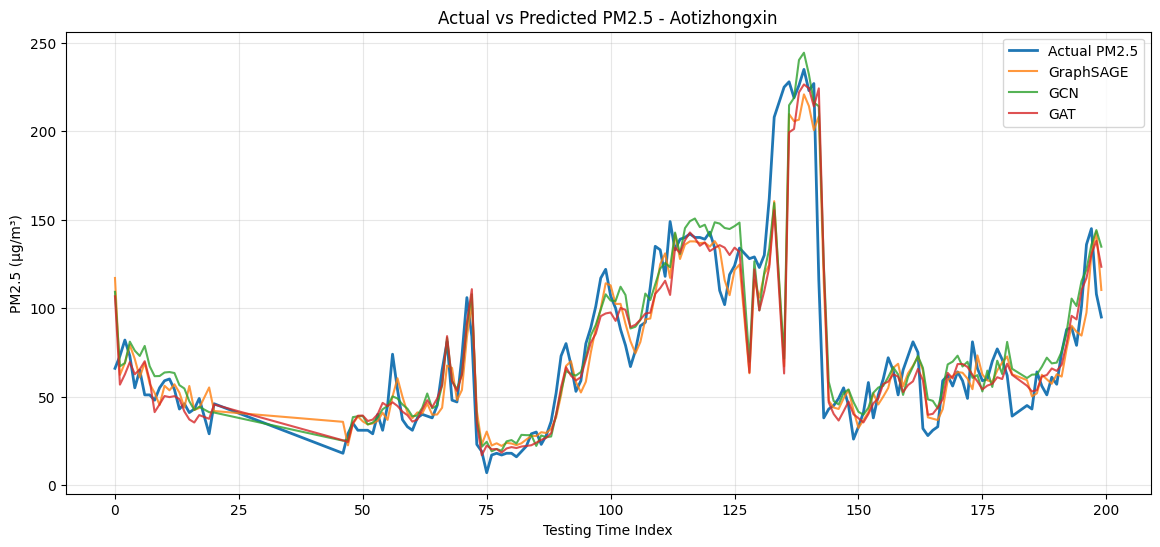

In [36]:
station_idx = 0
sample_size = 200

actual_scaled = y_test_t.numpy()

actual_plot = scaler_y.inverse_transform(
    actual_scaled.reshape(-1, 1)
).reshape(actual_scaled.shape)

mask_plot = mask_test_t.numpy()

plt.figure(figsize=(14, 6))

valid_indices = np.where(
    mask_plot[:sample_size, station_idx]
)[0]

plt.plot(
    valid_indices,
    actual_plot[:sample_size, station_idx][valid_indices],
    label="Actual PM2.5",
    linewidth=2
)

for name, pred in predictions_dict.items():

    plt.plot(
        valid_indices,
        pred[:sample_size, station_idx][valid_indices],
        label=name,
        alpha=0.8
    )

plt.title(
    f"Actual vs Predicted PM2.5 - {stations[station_idx]}"
)

plt.xlabel("Testing Time Index")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

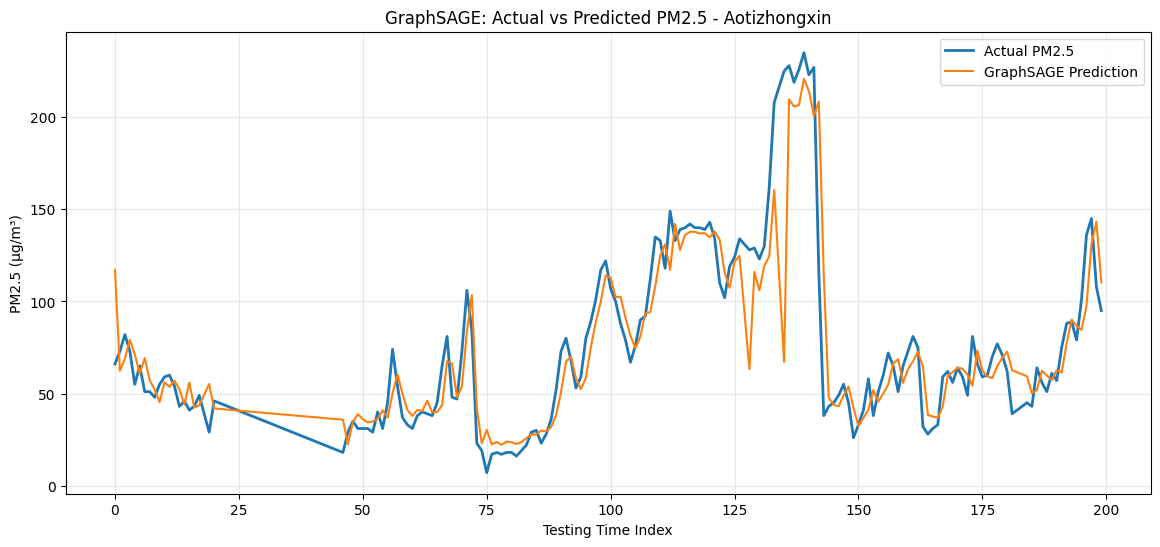

In [37]:
# 1. Menentukan stasiun
station_idx = 0
sample_size = 200

# 2. Mengambil nilai aktual PM2.5
graphsage_actual = scaler_y.inverse_transform(
    y_test_t.numpy().reshape(-1, 1)
).reshape(y_test_t.shape)

# 3. Mengambil hasil prediksi GraphSAGE
graphsage_pred_scaled = get_predictions(
    trained_models["GraphSAGE"],
    X_test_t
)

graphsage_pred = scaler_y.inverse_transform(
    graphsage_pred_scaled.reshape(-1, 1)
).reshape(graphsage_pred_scaled.shape)

# 4. Mengambil indeks target yang tersedia
mask = mask_test_t.numpy()

valid_indices = np.where(
    mask[:sample_size, station_idx]
)[0]

# 5. Membuat grafik
plt.figure(figsize=(14, 6))

plt.plot(
    valid_indices,
    graphsage_actual[:sample_size, station_idx][valid_indices],
    label="Actual PM2.5",
    linewidth=2
)

plt.plot(
    valid_indices,
    graphsage_pred[:sample_size, station_idx][valid_indices],
    label="GraphSAGE Prediction",
    linewidth=1.5
)

plt.title(
    f"GraphSAGE: Actual vs Predicted PM2.5 - {stations[station_idx]}"
)

plt.xlabel("Testing Time Index")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [38]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Menggunakan target yang tersedia
mask = mask_test_t.numpy()

y_true = graphsage_actual[mask]
y_pred = graphsage_pred[mask]

# Menghitung metrik
graphsage_mae = mean_absolute_error(
    y_true, y_pred
)

graphsage_rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

graphsage_r2 = r2_score(
    y_true, y_pred
)

# Menampilkan hasil
print("=== GRAPHSAGE EVALUATION ===")
print(f"MAE  : {graphsage_mae:.4f} µg/m³")
print(f"RMSE : {graphsage_rmse:.4f} µg/m³")
print(f"R2   : {graphsage_r2:.4f}")

=== GRAPHSAGE EVALUATION ===
MAE  : 11.2453 µg/m³
RMSE : 20.8470 µg/m³
R2   : 0.9494


## Random Sensor Failure

In [39]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_graphsage_failure(failed_stations):

    # Salin data testing agar data asli tidak berubah
    X_corrupted = X_test.copy()

    # Simulasi sensor gagal:
    # Semua fitur pada stasiun gagal diisi nol
    for station_idx in failed_stations:
        X_corrupted[:, station_idx, :] = 0.0

    # Prediksi menggunakan GraphSAGE yang sudah dilatih
    X_corrupted_t = torch.tensor(
        X_corrupted,
        dtype=torch.float32
    )

    pred_scaled = get_predictions(
        trained_models["GraphSAGE"],
        X_corrupted_t
    )

    # Kembalikan ke skala PM2.5 asli
    pred_original = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).reshape(pred_scaled.shape)

    # Evaluasi pada target yang tersedia
    mask = mask_test_t.numpy()

    y_true = graphsage_actual[mask]
    y_pred = pred_original[mask]

    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

In [40]:
import random

failure_levels = [0, 1, 3, 6, 9]
n_repetitions = 5

random_results = []

for n_failed in failure_levels:

    print(f"\nPengujian {n_failed} sensor gagal")

    for rep in range(n_repetitions):

        if n_failed == 0:
            failed_stations = []
        else:
            rng = random.Random(42 + rep)
            failed_stations = sorted(
                rng.sample(
                    range(num_stations),
                    n_failed
                )
            )

        mae, rmse, r2 = evaluate_graphsage_failure(
            failed_stations
        )

        random_results.append({
            "Failed Sensors": n_failed,
            "Failure Percentage": round(
                n_failed / num_stations * 100, 2
            ),
            "Repetition": rep + 1,
            "Failed Station Names": ", ".join(
                stations[i] for i in failed_stations
            ),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        print(
            f"Repetition {rep+1}: "
            f"MAE={mae:.4f}, "
            f"RMSE={rmse:.4f}, "
            f"R2={r2:.4f}"
        )

random_results_df = pd.DataFrame(random_results)

display(random_results_df.round(4))


Pengujian 0 sensor gagal
Repetition 1: MAE=11.2453, RMSE=20.8470, R2=0.9494
Repetition 2: MAE=11.2453, RMSE=20.8470, R2=0.9494
Repetition 3: MAE=11.2453, RMSE=20.8470, R2=0.9494
Repetition 4: MAE=11.2453, RMSE=20.8470, R2=0.9494
Repetition 5: MAE=11.2453, RMSE=20.8470, R2=0.9494

Pengujian 1 sensor gagal
Repetition 1: MAE=14.4821, RMSE=27.8901, R2=0.9094
Repetition 2: MAE=14.7185, RMSE=28.1938, R2=0.9074
Repetition 3: MAE=13.9782, RMSE=25.6670, R2=0.9233
Repetition 4: MAE=14.6854, RMSE=28.2978, R2=0.9068
Repetition 5: MAE=14.1324, RMSE=26.4138, R2=0.9188

Pengujian 3 sensor gagal
Repetition 1: MAE=22.7942, RMSE=41.0025, R2=0.8043
Repetition 2: MAE=21.9284, RMSE=38.6594, R2=0.8260
Repetition 3: MAE=21.2700, RMSE=38.7303, R2=0.8253
Repetition 4: MAE=21.3017, RMSE=38.8358, R2=0.8244
Repetition 5: MAE=21.9220, RMSE=38.6906, R2=0.8257

Pengujian 6 sensor gagal
Repetition 1: MAE=38.1220, RMSE=63.1164, R2=0.5362
Repetition 2: MAE=35.0154, RMSE=58.1992, R2=0.6056
Repetition 3: MAE=33.9727, RM

,Failed Sensors,Failure Percentage,Repetition,Failed Station Names,MAE,RMSE,R2
0,0,0.00,1,,11.2453,20.8470,0.9494
1,0,0.00,2,,11.2453,20.8470,0.9494
2,0,0.00,3,,11.2453,20.8470,0.9494
3,0,0.00,4,,11.2453,20.8470,0.9494
4,0,0.00,5,,11.2453,20.8470,0.9494
5,1,8.33,1,Wanliu,14.4821,27.8901,0.9094
6,1,8.33,2,Aotizhongxin,14.7185,28.1938,0.9074
7,1,8.33,3,Huairou,13.9782,25.6670,0.9233
8,1,8.33,4,Guanyuan,14.6854,28.2978,0.9068
9,1,8.33,5,Changping,14.1324,26.4138,0.9188


In [41]:
random_summary = (
    random_results_df
    .groupby(
        ["Failed Sensors", "Failure Percentage"]
    )[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
    .reset_index()
)

display(random_summary.round(4))

Failed Sensors Failure Percentage      MAE             RMSE              R2  \
                                        mean     std     mean     std    mean   
0              0               0.00  11.2453  0.0000  20.8470  0.0000  0.9494   
1              1               8.33  14.3993  0.3314  27.2925  1.1826  0.9131   
2              3              25.00  21.8433  0.6204  39.1837  1.0189  0.8211   
3              6              50.00  35.3252  1.7307  57.5679  3.3754  0.6131   
4              9              75.00  50.5547  0.7075  75.7301  1.6337  0.3320   

           
      std  
0  0.0000  
1  0.0074  
2  0.0095  
3  0.0464  
4  0.0289

In [42]:
baseline_mae = graphsage_mae
baseline_rmse = graphsage_rmse
baseline_r2 = graphsage_r2

degradation_rows = []

for _, row in random_results_df.groupby(
    ["Failed Sensors", "Failure Percentage"]
).mean(numeric_only=True).reset_index().iterrows():

    degradation_rows.append({
        "Failed Sensors": int(row["Failed Sensors"]),
        "Failure Percentage": row["Failure Percentage"],

        "MAE": row["MAE"],
        "RMSE": row["RMSE"],
        "R2": row["R2"],

        "MAE Degradation (%)": (
            (row["MAE"] - baseline_mae) /
            baseline_mae * 100
        ),

        "RMSE Degradation (%)": (
            (row["RMSE"] - baseline_rmse) /
            baseline_rmse * 100
        ),

        "R2 Degradation (%)": (
            (baseline_r2 - row["R2"]) /
            abs(baseline_r2) * 100
        )
    })

graphsage_random_summary = pd.DataFrame(
    degradation_rows
)

display(graphsage_random_summary.round(4))

,Failed Sensors,Failure Percentage,MAE,RMSE,R2,MAE Degradation (%),RMSE Degradation (%),R2 Degradation (%)
0,0,0.00,11.2453,20.8470,0.9494,0.0000,0.0000,0.0000
1,1,8.33,14.3993,27.2925,0.9131,28.0469,30.9179,3.8190
2,3,25.00,21.8433,39.1837,0.8211,94.2427,87.9583,13.5098
3,6,50.00,35.3252,57.5679,0.6131,214.1318,176.1446,35.4252
4,9,75.00,50.5547,75.7301,0.3320,349.5613,263.2658,65.0302


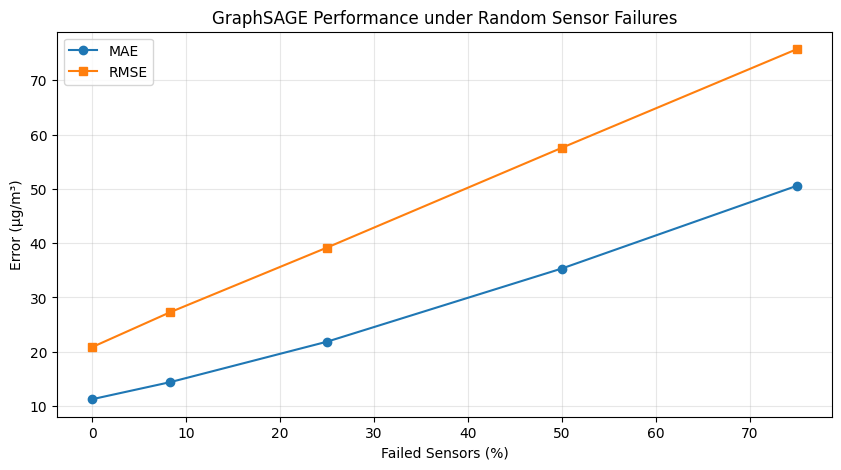

In [43]:
plt.figure(figsize=(10, 5))

plt.plot(
    graphsage_random_summary["Failure Percentage"],
    graphsage_random_summary["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    graphsage_random_summary["Failure Percentage"],
    graphsage_random_summary["RMSE"],
    marker="s",
    label="RMSE"
)

plt.title("GraphSAGE Performance under Random Sensor Failures")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("Error (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [44]:
def get_spatially_failed_stations(n_failed, center_idx=0):

    # Mengurutkan stasiun berdasarkan jarak dari pusat
    nearest_stations = np.argsort(
        distance_matrix[center_idx]
    )

    # Memilih sejumlah stasiun terdekat,
    # termasuk stasiun pusat
    failed_stations = nearest_stations[:n_failed]

    return failed_stations.tolist()


# Uji fungsi
for n in [1, 3, 6, 9]:

    failed = get_spatially_failed_stations(
        n,
        center_idx=0
    )

    print(f"\nJumlah sensor gagal: {n}")
    print([stations[i] for i in failed])


Jumlah sensor gagal: 1
['Aotizhongxin']

Jumlah sensor gagal: 3
['Aotizhongxin', 'Dongsi', 'Nongzhanguan']

Jumlah sensor gagal: 6
['Aotizhongxin', 'Dongsi', 'Nongzhanguan', 'Guanyuan', 'Wanliu', 'Tiantan']

Jumlah sensor gagal: 9
['Aotizhongxin', 'Dongsi', 'Nongzhanguan', 'Guanyuan', 'Wanliu', 'Tiantan', 'Wanshouxigong', 'Gucheng', 'Shunyi']


In [45]:
spatial_centers = [0, 5, 8]
failure_levels = [0, 1, 3, 6, 9]

spatial_results = []

for n_failed in failure_levels:

    for center_idx in spatial_centers:

        if n_failed == 0:
            failed_stations = []
        else:
            failed_stations = get_spatially_failed_stations(
                n_failed,
                center_idx
            )

        mae, rmse, r2 = evaluate_graphsage_failure(
            failed_stations
        )

        spatial_results.append({
            "Failed Sensors": n_failed,
            "Failure Percentage": round(
                n_failed / num_stations * 100, 2
            ),
            "Center Station": stations[center_idx],
            "Failed Stations": ", ".join(
                stations[i] for i in failed_stations
            ),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

spatial_results_df = pd.DataFrame(spatial_results)

display(spatial_results_df.round(4))

,Failed Sensors,Failure Percentage,Center Station,Failed Stations,MAE,RMSE,R2
0,0,0.00,Aotizhongxin,,11.2453,20.8470,0.9494
1,0,0.00,Gucheng,,11.2453,20.8470,0.9494
2,0,0.00,Shunyi,,11.2453,20.8470,0.9494
3,1,8.33,Aotizhongxin,Aotizhongxin,14.7185,28.1938,0.9074
4,1,8.33,Gucheng,Gucheng,14.3234,29.4215,0.8992
5,1,8.33,Shunyi,Shunyi,14.2467,28.0041,0.9087
6,3,25.00,Aotizhongxin,"Aotizhongxin, Dongsi, Nongzhanguan",23.8899,45.3868,0.7602
7,3,25.00,Gucheng,"Gucheng, Wanliu, Guanyuan",23.1024,44.1680,0.7729
8,3,25.00,Shunyi,"Shunyi, Huairou, Nongzhanguan",21.8021,40.7325,0.8068
9,6,50.00,Aotizhongxin,"Aotizhongxin, Dongsi, Nongzhanguan, Guanyuan, ...",38.8631,65.1184,0.5063


In [46]:
graphsage_spatial_summary = (
    spatial_results_df
    .groupby(
        ["Failed Sensors", "Failure Percentage"]
    )[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

graphsage_spatial_summary["MAE Degradation (%)"] = (
    (graphsage_spatial_summary["MAE"] - graphsage_mae)
    / graphsage_mae * 100
)

graphsage_spatial_summary["RMSE Degradation (%)"] = (
    (graphsage_spatial_summary["RMSE"] - graphsage_rmse)
    / graphsage_rmse * 100
)

graphsage_spatial_summary["R2 Degradation (%)"] = (
    (graphsage_r2 - graphsage_spatial_summary["R2"])
    / abs(graphsage_r2) * 100
)

display(graphsage_spatial_summary.round(4))

graphsage_spatial_summary.to_csv(
    "GraphSAGE_Spatial_Failure.csv",
    index=False
)

print("Hasil GraphSAGE berhasil disimpan!")

,Failed Sensors,Failure Percentage,MAE,RMSE,R2,MAE Degradation (%),RMSE Degradation (%),R2 Degradation (%)
0,0,0.00,11.2453,20.8470,0.9494,0.0000,0.0000,0.0000
1,1,8.33,14.4295,28.5398,0.9051,28.3157,36.9011,4.6642
2,3,25.00,22.9315,43.4291,0.7799,103.9198,108.3227,17.8484
3,6,50.00,37.6385,63.6749,0.5276,234.7031,205.4386,44.4262
4,9,75.00,52.6032,81.1392,0.2327,367.7775,289.2122,75.4910


Hasil GraphSAGE berhasil disimpan!


In [47]:
graphsage_spatial_summary.to_csv(
    "GraphSAGE_Spatial_Summary.csv",
    index=False
)

spatial_results_df.to_csv(
    "GraphSAGE_Spatial_Detail.csv",
    index=False
)

random_results_df.to_csv(
    "GraphSAGE_Random_Detail.csv",
    index=False
)

print("Seluruh hasil eksperimen GraphSAGE berhasil disimpan!")

Seluruh hasil eksperimen GraphSAGE berhasil disimpan!


# Implementasi algoritma GCN


In [48]:
print("Model GCN tersedia:",
      "GCN" in trained_models)

print("Model:", trained_models["GCN"])

Model GCN tersedia: True
Model: GCNModel(
  (conv1): GCNConv(13, 32)
  (conv2): GCNConv(32, 32)
  (output): Linear(in_features=32, out_features=1, bias=True)
)


In [49]:
# Prediksi GCN pada data testing
gcn_pred_scaled = get_predictions(
    trained_models["GCN"],
    X_test_t
)

# Mengembalikan prediksi ke skala asli
gcn_pred = scaler_y.inverse_transform(
    gcn_pred_scaled.reshape(-1, 1)
).reshape(gcn_pred_scaled.shape)

# Mengambil nilai aktual
gcn_actual = scaler_y.inverse_transform(
    y_test_t.numpy().reshape(-1, 1)
).reshape(y_test_t.shape)

# Masking target yang tersedia
gcn_mask = mask_test_t.numpy()

y_true_gcn = gcn_actual[gcn_mask]
y_pred_gcn = gcn_pred[gcn_mask]

In [50]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

gcn_mae = mean_absolute_error(
    y_true_gcn,
    y_pred_gcn
)

gcn_rmse = np.sqrt(
    mean_squared_error(
        y_true_gcn,
        y_pred_gcn
    )
)

gcn_r2 = r2_score(
    y_true_gcn,
    y_pred_gcn
)

print("=== GCN EVALUATION ===")
print(f"MAE  : {gcn_mae:.4f} µg/m³")
print(f"RMSE : {gcn_rmse:.4f} µg/m³")
print(f"R2   : {gcn_r2:.4f}")

=== GCN EVALUATION ===
MAE  : 14.7327 µg/m³
RMSE : 26.3774 µg/m³
R2   : 0.9190


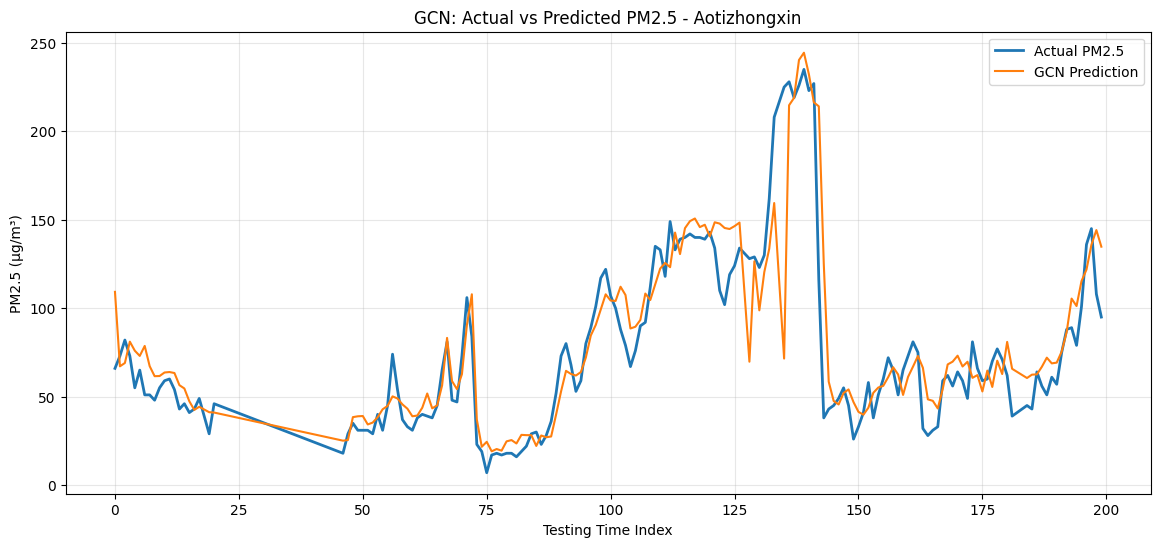

In [51]:
station_idx = 0
sample_size = 200

valid_indices = np.where(
    gcn_mask[:sample_size, station_idx]
)[0]

plt.figure(figsize=(14, 6))

plt.plot(
    valid_indices,
    gcn_actual[:sample_size, station_idx][valid_indices],
    label="Actual PM2.5",
    linewidth=2
)

plt.plot(
    valid_indices,
    gcn_pred[:sample_size, station_idx][valid_indices],
    label="GCN Prediction",
    linewidth=1.5
)

plt.title(
    f"GCN: Actual vs Predicted PM2.5 - {stations[station_idx]}"
)

plt.xlabel("Testing Time Index")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [52]:
def evaluate_gcn_failure(failed_stations):

    # Salin data testing
    X_corrupted = X_test.copy()

    # Simulasi kegagalan sensor
    for station_idx in failed_stations:
        X_corrupted[:, station_idx, :] = 0.0

    # Konversi ke tensor
    X_corrupted_t = torch.tensor(
        X_corrupted,
        dtype=torch.float32
    )

    # Prediksi menggunakan model GCN
    pred_scaled = get_predictions(
        trained_models["GCN"],
        X_corrupted_t
    )

    # Mengembalikan ke skala PM2.5 asli
    pred_original = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).reshape(pred_scaled.shape)

    # Evaluasi menggunakan target yang tersedia
    mask = mask_test_t.numpy()

    y_true = gcn_actual[mask]
    y_pred = pred_original[mask]

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

In [53]:
import random

failure_levels = [0, 1, 3, 6, 9]
n_repetitions = 5

gcn_random_results = []

for n_failed in failure_levels:

    print(f"\nPengujian {n_failed} sensor gagal")

    for rep in range(n_repetitions):

        if n_failed == 0:
            failed_stations = []

        else:
            rng = random.Random(42 + rep)

            failed_stations = sorted(
                rng.sample(
                    range(num_stations),
                    n_failed
                )
            )

        mae, rmse, r2 = evaluate_gcn_failure(
            failed_stations
        )

        gcn_random_results.append({
            "Failed Sensors": n_failed,

            "Failure Percentage": round(
                n_failed / num_stations * 100, 2
            ),

            "Repetition": rep + 1,

            "Failed Station Names": ", ".join(
                stations[i] for i in failed_stations
            ),

            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        print(
            f"Repetition {rep+1} | "
            f"MAE: {mae:.4f} | "
            f"RMSE: {rmse:.4f} | "
            f"R2: {r2:.4f}"
        )

gcn_random_results_df = pd.DataFrame(
    gcn_random_results
)

display(gcn_random_results_df.round(4))


Pengujian 0 sensor gagal
Repetition 1 | MAE: 14.7327 | RMSE: 26.3774 | R2: 0.9190
Repetition 2 | MAE: 14.7327 | RMSE: 26.3774 | R2: 0.9190
Repetition 3 | MAE: 14.7327 | RMSE: 26.3774 | R2: 0.9190
Repetition 4 | MAE: 14.7327 | RMSE: 26.3774 | R2: 0.9190
Repetition 5 | MAE: 14.7327 | RMSE: 26.3774 | R2: 0.9190

Pengujian 1 sensor gagal
Repetition 1 | MAE: 15.4363 | RMSE: 26.9328 | R2: 0.9155
Repetition 2 | MAE: 15.5080 | RMSE: 27.0879 | R2: 0.9146
Repetition 3 | MAE: 16.0223 | RMSE: 27.2914 | R2: 0.9133
Repetition 4 | MAE: 15.8425 | RMSE: 27.6978 | R2: 0.9107
Repetition 5 | MAE: 15.8662 | RMSE: 27.2165 | R2: 0.9138

Pengujian 3 sensor gagal
Repetition 1 | MAE: 21.1237 | RMSE: 33.5934 | R2: 0.8686
Repetition 2 | MAE: 21.1013 | RMSE: 33.0457 | R2: 0.8729
Repetition 3 | MAE: 20.4346 | RMSE: 33.0502 | R2: 0.8728
Repetition 4 | MAE: 20.7405 | RMSE: 33.2620 | R2: 0.8712
Repetition 5 | MAE: 21.1711 | RMSE: 33.3874 | R2: 0.8702

Pengujian 6 sensor gagal
Repetition 1 | MAE: 35.7573 | RMSE: 54.33

,Failed Sensors,Failure Percentage,Repetition,Failed Station Names,MAE,RMSE,R2
0,0,0.00,1,,14.7327,26.3774,0.9190
1,0,0.00,2,,14.7327,26.3774,0.9190
2,0,0.00,3,,14.7327,26.3774,0.9190
3,0,0.00,4,,14.7327,26.3774,0.9190
4,0,0.00,5,,14.7327,26.3774,0.9190
5,1,8.33,1,Wanliu,15.4363,26.9328,0.9155
6,1,8.33,2,Aotizhongxin,15.5080,27.0879,0.9146
7,1,8.33,3,Huairou,16.0223,27.2914,0.9133
8,1,8.33,4,Guanyuan,15.8425,27.6978,0.9107
9,1,8.33,5,Changping,15.8662,27.2165,0.9138


## random sensor failure


In [54]:
gcn_random_summary = (
    gcn_random_results_df
    .groupby(
        ["Failed Sensors", "Failure Percentage"]
    )[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
    .reset_index()
)

display(gcn_random_summary.round(4))

Failed Sensors Failure Percentage      MAE             RMSE              R2  \
                                        mean     std     mean     std    mean   
0              0               0.00  14.7327  0.0000  26.3774  0.0000  0.9190   
1              1               8.33  15.7351  0.2510  27.2453  0.2873  0.9136   
2              3              25.00  20.9142  0.3182  33.2677  0.2329  0.8711   
3              6              50.00  33.3860  1.6031  49.3453  2.9736  0.7157   
4              9              75.00  47.9344  0.7866  68.9609  1.9558  0.4459   

           
      std  
0  0.0000  
1  0.0018  
2  0.0018  
3  0.0352  
4  0.0316

In [55]:
gcn_baseline_mae = gcn_mae
gcn_baseline_rmse = gcn_rmse
gcn_baseline_r2 = gcn_r2

gcn_random_degradation = (
    gcn_random_results_df
    .groupby(
        ["Failed Sensors", "Failure Percentage"]
    )[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

gcn_random_degradation["MAE Degradation (%)"] = (
    (gcn_random_degradation["MAE"] - gcn_baseline_mae)
    / gcn_baseline_mae * 100
)

gcn_random_degradation["RMSE Degradation (%)"] = (
    (gcn_random_degradation["RMSE"] - gcn_baseline_rmse)
    / gcn_baseline_rmse * 100
)

gcn_random_degradation["R2 Degradation (%)"] = (
    (gcn_baseline_r2 - gcn_random_degradation["R2"])
    / abs(gcn_baseline_r2) * 100
)

display(gcn_random_degradation.round(4))

,Failed Sensors,Failure Percentage,MAE,RMSE,R2,MAE Degradation (%),RMSE Degradation (%),R2 Degradation (%)
0,0,0.00,14.7327,26.3774,0.9190,0.0000,0.0000,0.0000
1,1,8.33,15.7351,27.2453,0.9136,6.8035,3.2902,0.5905
2,3,25.00,20.9142,33.2677,0.8711,41.9577,26.1221,5.2074
3,6,50.00,33.3860,49.3453,0.7157,126.6113,87.0741,22.1246
4,9,75.00,47.9344,68.9609,0.4459,225.3599,161.4393,51.4755


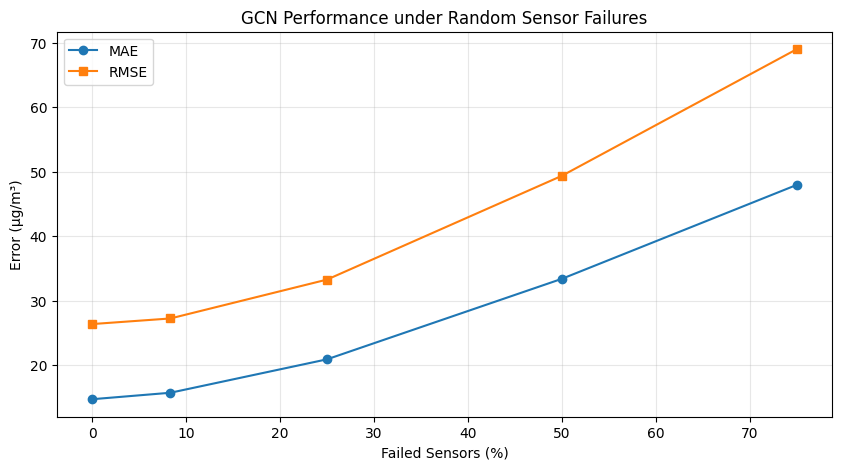

In [56]:
plt.figure(figsize=(10, 5))

plt.plot(
    gcn_random_degradation["Failure Percentage"],
    gcn_random_degradation["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    gcn_random_degradation["Failure Percentage"],
    gcn_random_degradation["RMSE"],
    marker="s",
    label="RMSE"
)

plt.title("GCN Performance under Random Sensor Failures")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("Error (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [57]:
gcn_random_results_df.to_csv(
    "GCN_Random_Failure_Detail.csv",
    index=False
)

gcn_random_degradation.to_csv(
    "GCN_Random_Failure_Summary.csv",
    index=False
)

print("Hasil Random Sensor Failure GCN berhasil disimpan!")

Hasil Random Sensor Failure GCN berhasil disimpan!


## Spatially Localized Sensor Failure

In [58]:
# Memastikan fungsi pemilihan stasiun tersedia
def get_spatially_failed_stations(n_failed, center_idx=0):

    nearest_stations = np.argsort(
        distance_matrix[center_idx]
    )

    return nearest_stations[:n_failed].tolist()


# Konfigurasi eksperimen
spatial_centers = [0, 5, 8]
failure_levels = [0, 1, 3, 6, 9]

gcn_spatial_results = []

# Menjalankan eksperimen
for n_failed in failure_levels:

    for center_idx in spatial_centers:

        if n_failed == 0:
            failed_stations = []
        else:
            failed_stations = get_spatially_failed_stations(
                n_failed,
                center_idx
            )

        mae, rmse, r2 = evaluate_gcn_failure(
            failed_stations
        )

        gcn_spatial_results.append({
            "Failed Sensors": n_failed,
            "Failure Percentage": round(
                n_failed / num_stations * 100, 2
            ),
            "Center Station": stations[center_idx],
            "Failed Stations": ", ".join(
                stations[i] for i in failed_stations
            ),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

gcn_spatial_results_df = pd.DataFrame(
    gcn_spatial_results
)

print("SPATIAL FAILURE GCN BERHASIL!")
print("Jumlah skenario:", len(gcn_spatial_results_df))

display(gcn_spatial_results_df.round(4))

SPATIAL FAILURE GCN BERHASIL!
Jumlah skenario: 15


,Failed Sensors,Failure Percentage,Center Station,Failed Stations,MAE,RMSE,R2
0,0,0.00,Aotizhongxin,,14.7327,26.3774,0.9190
1,0,0.00,Gucheng,,14.7327,26.3774,0.9190
2,0,0.00,Shunyi,,14.7327,26.3774,0.9190
3,1,8.33,Aotizhongxin,Aotizhongxin,15.5080,27.0879,0.9146
4,1,8.33,Gucheng,Gucheng,15.7375,28.2191,0.9073
5,1,8.33,Shunyi,Shunyi,15.7228,27.6706,0.9109
6,3,25.00,Aotizhongxin,"Aotizhongxin, Dongsi, Nongzhanguan",22.4709,37.4785,0.8365
7,3,25.00,Gucheng,"Gucheng, Wanliu, Guanyuan",21.2948,35.8972,0.8500
8,3,25.00,Shunyi,"Shunyi, Huairou, Nongzhanguan",20.3875,33.8777,0.8664
9,6,50.00,Aotizhongxin,"Aotizhongxin, Dongsi, Nongzhanguan, Guanyuan, ...",36.3017,57.1567,0.6196


In [59]:
gcn_spatial_degradation = (
    gcn_spatial_results_df
    .groupby(
        ["Failed Sensors", "Failure Percentage"]
    )[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

gcn_spatial_degradation["MAE Degradation (%)"] = (
    (gcn_spatial_degradation["MAE"] - gcn_mae)
    / gcn_mae * 100
)

gcn_spatial_degradation["RMSE Degradation (%)"] = (
    (gcn_spatial_degradation["RMSE"] - gcn_rmse)
    / gcn_rmse * 100
)

gcn_spatial_degradation["R2 Degradation (%)"] = (
    (gcn_r2 - gcn_spatial_degradation["R2"])
    / abs(gcn_r2) * 100
)

display(gcn_spatial_degradation.round(4))

,Failed Sensors,Failure Percentage,MAE,RMSE,R2,MAE Degradation (%),RMSE Degradation (%),R2 Degradation (%)
0,0,0.00,14.7327,26.3774,0.9190,0.0000,0.0000,0.0000
1,1,8.33,15.6561,27.6592,0.9109,6.2675,4.8595,0.8803
2,3,25.00,21.3844,35.7511,0.8509,45.1489,35.5370,7.4060
3,6,50.00,34.6890,55.0143,0.6470,135.4554,108.5659,29.5955
4,9,75.00,50.0961,75.5492,0.3340,240.0324,186.4163,63.6574


In [60]:
gcn_spatial_results_df.to_csv(
    "GCN_Spatial_Failure_Detail.csv",
    index=False
)

gcn_spatial_degradation.to_csv(
    "GCN_Spatial_Failure_Summary.csv",
    index=False
)

print("Hasil Spatial Failure GCN berhasil disimpan!")

Hasil Spatial Failure GCN berhasil disimpan!


In [61]:
# Rata-rata hasil Random Failure
gcn_random_mean = (
    gcn_random_results_df
    .groupby("Failure Percentage")[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

# Rata-rata hasil Spatial Failure
gcn_spatial_mean = (
    gcn_spatial_results_df
    .groupby("Failure Percentage")[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

# Menggabungkan kedua skenario
gcn_scenario_comparison = gcn_random_mean.merge(
    gcn_spatial_mean,
    on="Failure Percentage",
    suffixes=("_Random", "_Spatial")
)

display(gcn_scenario_comparison.round(4))

,Failure Percentage,MAE_Random,RMSE_Random,R2_Random,MAE_Spatial,RMSE_Spatial,R2_Spatial
0,0.00,14.7327,26.3774,0.9190,14.7327,26.3774,0.9190
1,8.33,15.7351,27.2453,0.9136,15.6561,27.6592,0.9109
2,25.00,20.9142,33.2677,0.8711,21.3844,35.7511,0.8509
3,50.00,33.3860,49.3453,0.7157,34.6890,55.0143,0.6470
4,75.00,47.9344,68.9609,0.4459,50.0961,75.5492,0.3340


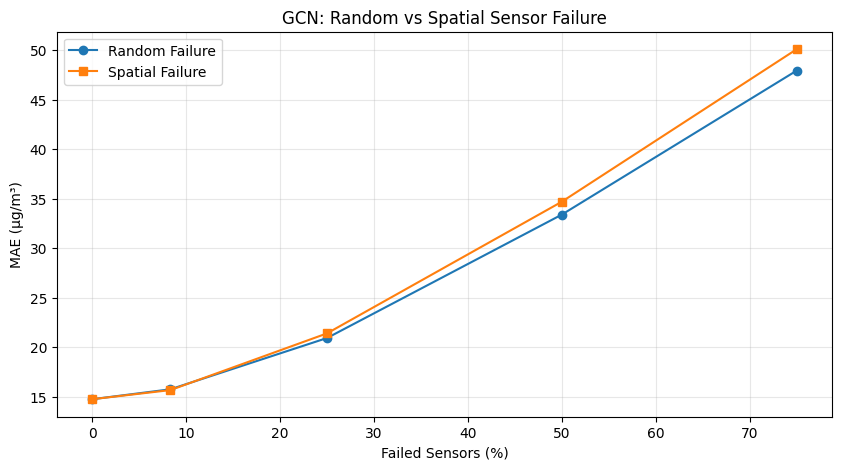

In [62]:
plt.figure(figsize=(10, 5))

plt.plot(
    gcn_scenario_comparison["Failure Percentage"],
    gcn_scenario_comparison["MAE_Random"],
    marker="o",
    label="Random Failure"
)

plt.plot(
    gcn_scenario_comparison["Failure Percentage"],
    gcn_scenario_comparison["MAE_Spatial"],
    marker="s",
    label="Spatial Failure"
)

plt.title("GCN: Random vs Spatial Sensor Failure")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("MAE (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [63]:
gcn_files = {
    "GCN_Normal_Baseline.csv": pd.DataFrame([{
        "Algorithm": "GCN",
        "MAE": gcn_mae,
        "RMSE": gcn_rmse,
        "R2": gcn_r2
    }]),

    "GCN_Random_Detail.csv": gcn_random_results_df,
    "GCN_Random_Summary.csv": gcn_random_degradation,
    "GCN_Spatial_Detail.csv": gcn_spatial_results_df,
    "GCN_Spatial_Summary.csv": gcn_spatial_degradation,
    "GCN_Random_vs_Spatial.csv": gcn_scenario_comparison
}

for filename, dataframe in gcn_files.items():
    dataframe.to_csv(filename, index=False)

print("Seluruh file eksperimen GCN berhasil disimpan!")

Seluruh file eksperimen GCN berhasil disimpan!


# Implementasi Algoritma GCT


In [64]:
print("Model GAT tersedia:", "GAT" in trained_models)
print(trained_models["GAT"])

Model GAT tersedia: True
GATModel(
  (conv1): GATConv(13, 8, heads=4)
  (conv2): GATConv(32, 32, heads=1)
  (output): Linear(in_features=32, out_features=1, bias=True)
)


In [65]:
gat_pred_scaled = get_predictions(
    trained_models["GAT"],
    X_test_t
)

gat_pred = scaler_y.inverse_transform(
    gat_pred_scaled.reshape(-1, 1)
).reshape(gat_pred_scaled.shape)

gat_actual = scaler_y.inverse_transform(
    y_test_t.numpy().reshape(-1, 1)
).reshape(y_test_t.shape)

gat_mask = mask_test_t.numpy()

y_true_gat = gat_actual[gat_mask]
y_pred_gat = gat_pred[gat_mask]

In [66]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

gat_mae = mean_absolute_error(
    y_true_gat, y_pred_gat
)

gat_rmse = np.sqrt(
    mean_squared_error(y_true_gat, y_pred_gat)
)

gat_r2 = r2_score(
    y_true_gat, y_pred_gat
)

print("=== GAT EVALUATION ===")
print(f"MAE  : {gat_mae:.4f} µg/m³")
print(f"RMSE : {gat_rmse:.4f} µg/m³")
print(f"R2   : {gat_r2:.4f}")

=== GAT EVALUATION ===
MAE  : 12.7531 µg/m³
RMSE : 23.9496 µg/m³
R2   : 0.9332


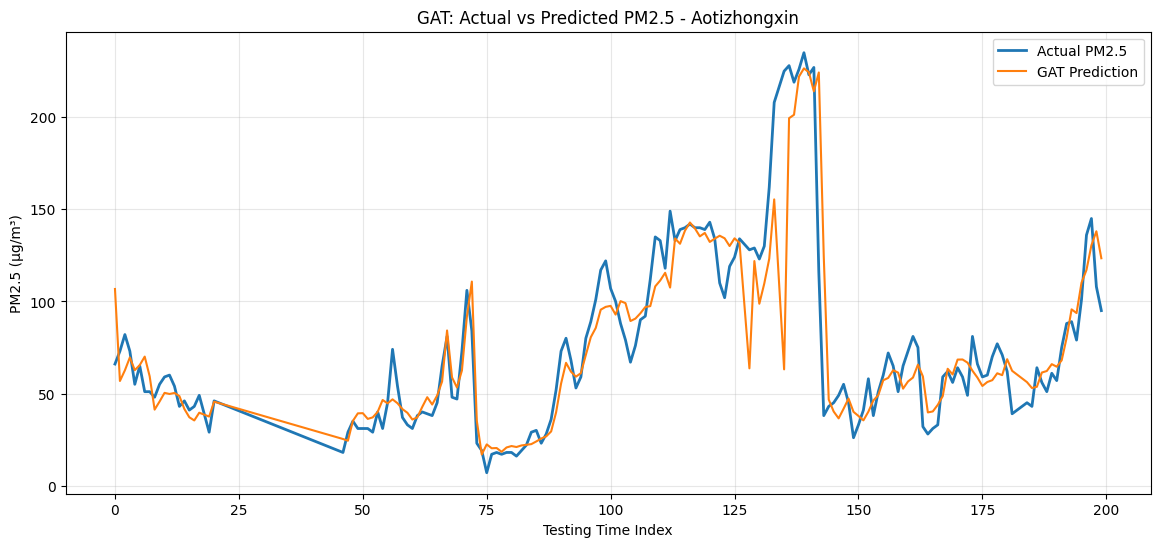

In [67]:
station_idx = 0
sample_size = 200

valid_indices = np.where(
    gat_mask[:sample_size, station_idx]
)[0]

plt.figure(figsize=(14, 6))

plt.plot(
    valid_indices,
    gat_actual[:sample_size, station_idx][valid_indices],
    label="Actual PM2.5",
    linewidth=2
)

plt.plot(
    valid_indices,
    gat_pred[:sample_size, station_idx][valid_indices],
    label="GAT Prediction",
    linewidth=1.5
)

plt.title(
    f"GAT: Actual vs Predicted PM2.5 - {stations[station_idx]}"
)

plt.xlabel("Testing Time Index")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [68]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

gat_mae = mean_absolute_error(
    gat_actual[gat_mask],
    gat_pred[gat_mask]
)

gat_rmse = np.sqrt(
    mean_squared_error(
        gat_actual[gat_mask],
        gat_pred[gat_mask]
    )
)

gat_r2 = r2_score(
    gat_actual[gat_mask],
    gat_pred[gat_mask]
)

print("=== GAT EVALUATION ===")
print(f"MAE  : {gat_mae:.4f} µg/m³")
print(f"RMSE : {gat_rmse:.4f} µg/m³")
print(f"R2   : {gat_r2:.4f}")

=== GAT EVALUATION ===
MAE  : 12.7531 µg/m³
RMSE : 23.9496 µg/m³
R2   : 0.9332


## Random Sensor Failure pada GAT

In [69]:
def evaluate_gat_failure(failed_stations):

    # Salin data testing
    X_corrupted = X_test.copy()

    # Simulasi kegagalan sensor
    for station_idx in failed_stations:
        X_corrupted[:, station_idx, :] = 0.0

    # Konversi ke tensor
    X_corrupted_t = torch.tensor(
        X_corrupted,
        dtype=torch.float32
    )

    # Prediksi menggunakan GAT
    pred_scaled = get_predictions(
        trained_models["GAT"],
        X_corrupted_t
    )

    # Mengembalikan ke skala PM2.5 asli
    pred_original = scaler_y.inverse_transform(
        pred_scaled.reshape(-1, 1)
    ).reshape(pred_scaled.shape)

    # Evaluasi target yang tersedia
    mask = mask_test_t.numpy()

    y_true = gat_actual[mask]
    y_pred = pred_original[mask]

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    r2 = r2_score(y_true, y_pred)

    return mae, rmse, r2

In [70]:
import random

failure_levels = [0, 1, 3, 6, 9]
n_repetitions = 5

gat_random_results = []

for n_failed in failure_levels:

    print(f"\nPengujian {n_failed} sensor gagal")

    for rep in range(n_repetitions):

        if n_failed == 0:
            failed_stations = []

        else:
            rng = random.Random(42 + rep)

            failed_stations = sorted(
                rng.sample(
                    range(num_stations),
                    n_failed
                )
            )

        mae, rmse, r2 = evaluate_gat_failure(
            failed_stations
        )

        gat_random_results.append({
            "Failed Sensors": n_failed,

            "Failure Percentage": round(
                n_failed / num_stations * 100, 2
            ),

            "Repetition": rep + 1,

            "Failed Station Names": ", ".join(
                stations[i] for i in failed_stations
            ),

            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

        print(
            f"Repetition {rep+1} | "
            f"MAE: {mae:.4f} | "
            f"RMSE: {rmse:.4f} | "
            f"R2: {r2:.4f}"
        )

gat_random_results_df = pd.DataFrame(
    gat_random_results
)

display(gat_random_results_df.round(4))


Pengujian 0 sensor gagal
Repetition 1 | MAE: 12.7531 | RMSE: 23.9496 | R2: 0.9332
Repetition 2 | MAE: 12.7531 | RMSE: 23.9496 | R2: 0.9332
Repetition 3 | MAE: 12.7531 | RMSE: 23.9496 | R2: 0.9332
Repetition 4 | MAE: 12.7531 | RMSE: 23.9496 | R2: 0.9332
Repetition 5 | MAE: 12.7531 | RMSE: 23.9496 | R2: 0.9332

Pengujian 1 sensor gagal
Repetition 1 | MAE: 14.2019 | RMSE: 26.6323 | R2: 0.9174
Repetition 2 | MAE: 14.9847 | RMSE: 27.5883 | R2: 0.9114
Repetition 3 | MAE: 13.9588 | RMSE: 25.4218 | R2: 0.9248
Repetition 4 | MAE: 16.6399 | RMSE: 30.4591 | R2: 0.8920
Repetition 5 | MAE: 13.9792 | RMSE: 25.5281 | R2: 0.9241

Pengujian 3 sensor gagal
Repetition 1 | MAE: 20.1106 | RMSE: 35.5370 | R2: 0.8530
Repetition 2 | MAE: 24.4076 | RMSE: 41.0291 | R2: 0.8040
Repetition 3 | MAE: 18.9800 | RMSE: 34.3477 | R2: 0.8626
Repetition 4 | MAE: 23.8754 | RMSE: 40.5146 | R2: 0.8089
Repetition 5 | MAE: 19.2074 | RMSE: 32.6830 | R2: 0.8756

Pengujian 6 sensor gagal
Repetition 1 | MAE: 33.7017 | RMSE: 53.25

,Failed Sensors,Failure Percentage,Repetition,Failed Station Names,MAE,RMSE,R2
0,0,0.00,1,,12.7531,23.9496,0.9332
1,0,0.00,2,,12.7531,23.9496,0.9332
2,0,0.00,3,,12.7531,23.9496,0.9332
3,0,0.00,4,,12.7531,23.9496,0.9332
4,0,0.00,5,,12.7531,23.9496,0.9332
5,1,8.33,1,Wanliu,14.2019,26.6323,0.9174
6,1,8.33,2,Aotizhongxin,14.9847,27.5883,0.9114
7,1,8.33,3,Huairou,13.9588,25.4218,0.9248
8,1,8.33,4,Guanyuan,16.6399,30.4591,0.8920
9,1,8.33,5,Changping,13.9792,25.5281,0.9241


In [71]:
gat_random_summary = (
    gat_random_results_df
    .groupby(
        ["Failed Sensors", "Failure Percentage"]
    )[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
    .reset_index()
)

display(gat_random_summary.round(4))

Failed Sensors Failure Percentage      MAE             RMSE              R2  \
                                        mean     std     mean     std    mean   
0              0               0.00  12.7531  0.0000  23.9496  0.0000  0.9332   
1              1               8.33  14.7529  1.1344  27.1259  2.0631  0.9139   
2              3              25.00  21.3162  2.6204  36.8223  3.7496  0.8408   
3              6              50.00  34.2446  2.2196  53.1699  3.9439  0.6694   
4              9              75.00  48.6316  4.4708  71.7553  5.9189  0.3972   

           
      std  
0  0.0000  
1  0.0134  
2  0.0324  
3  0.0507  
4  0.0976

In [72]:
gat_baseline_mae = gat_mae
gat_baseline_rmse = gat_rmse
gat_baseline_r2 = gat_r2

gat_random_degradation = (
    gat_random_results_df
    .groupby(
        ["Failed Sensors", "Failure Percentage"]
    )[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

gat_random_degradation["MAE Degradation (%)"] = (
    (gat_random_degradation["MAE"] - gat_baseline_mae)
    / gat_baseline_mae * 100
)

gat_random_degradation["RMSE Degradation (%)"] = (
    (gat_random_degradation["RMSE"] - gat_baseline_rmse)
    / gat_baseline_rmse * 100
)

gat_random_degradation["R2 Degradation (%)"] = (
    (gat_baseline_r2 - gat_random_degradation["R2"])
    / abs(gat_baseline_r2) * 100
)

display(gat_random_degradation.round(4))

,Failed Sensors,Failure Percentage,MAE,RMSE,R2,MAE Degradation (%),RMSE Degradation (%),R2 Degradation (%)
0,0,0.00,12.7531,23.9496,0.9332,0.0000,0.0000,0.0000
1,1,8.33,14.7529,27.1259,0.9139,15.6808,13.2626,2.0666
2,3,25.00,21.3162,36.8223,0.8408,67.1451,53.7491,9.9007
3,6,50.00,34.2446,53.1699,0.6694,168.5196,122.0075,28.2705
4,9,75.00,48.6316,71.7553,0.3972,281.3313,199.6098,57.4327


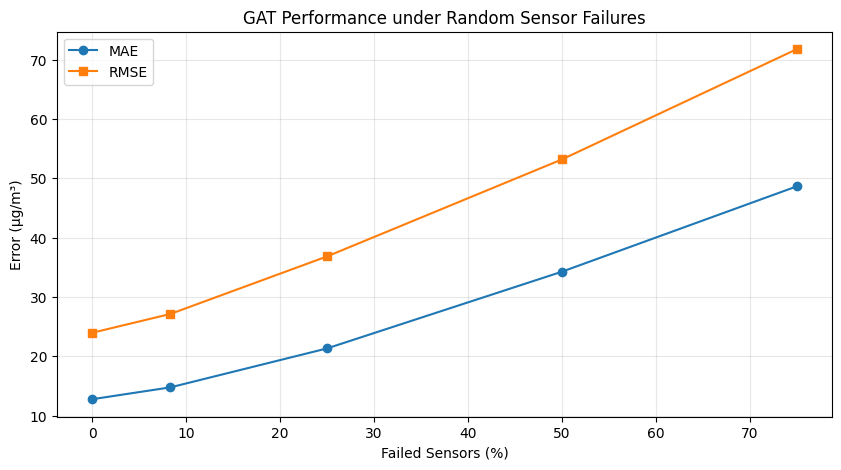

In [73]:
plt.figure(figsize=(10, 5))

plt.plot(
    gat_random_degradation["Failure Percentage"],
    gat_random_degradation["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    gat_random_degradation["Failure Percentage"],
    gat_random_degradation["RMSE"],
    marker="s",
    label="RMSE"
)

plt.title("GAT Performance under Random Sensor Failures")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("Error (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [74]:
gat_random_results_df.to_csv(
    "GAT_Random_Failure_Detail.csv",
    index=False
)

gat_random_degradation.to_csv(
    "GAT_Random_Failure_Summary.csv",
    index=False
)

print("Hasil Random Sensor Failure GAT berhasil disimpan!")

Hasil Random Sensor Failure GAT berhasil disimpan!


## Spatially Localized Sensor Failure

In [75]:
spatial_centers = [0, 5, 8]
failure_levels = [0, 1, 3, 6, 9]

gat_spatial_results = []

for n_failed in failure_levels:

    for center_idx in spatial_centers:

        if n_failed == 0:
            failed_stations = []
        else:
            failed_stations = get_spatially_failed_stations(
                n_failed,
                center_idx
            )

        mae, rmse, r2 = evaluate_gat_failure(
            failed_stations
        )

        gat_spatial_results.append({
            "Failed Sensors": n_failed,
            "Failure Percentage": round(
                n_failed / num_stations * 100, 2
            ),
            "Center Station": stations[center_idx],
            "Failed Stations": ", ".join(
                stations[i] for i in failed_stations
            ),
            "MAE": mae,
            "RMSE": rmse,
            "R2": r2
        })

gat_spatial_results_df = pd.DataFrame(
    gat_spatial_results
)

print("SPATIAL FAILURE GAT BERHASIL!")
print("Jumlah skenario:", len(gat_spatial_results_df))

display(gat_spatial_results_df.round(4))

SPATIAL FAILURE GAT BERHASIL!
Jumlah skenario: 15


,Failed Sensors,Failure Percentage,Center Station,Failed Stations,MAE,RMSE,R2
0,0,0.00,Aotizhongxin,,12.7531,23.9496,0.9332
1,0,0.00,Gucheng,,12.7531,23.9496,0.9332
2,0,0.00,Shunyi,,12.7531,23.9496,0.9332
3,1,8.33,Aotizhongxin,Aotizhongxin,14.9847,27.5883,0.9114
4,1,8.33,Gucheng,Gucheng,14.3851,27.3393,0.9130
5,1,8.33,Shunyi,Shunyi,14.1287,27.2469,0.9136
6,3,25.00,Aotizhongxin,"Aotizhongxin, Dongsi, Nongzhanguan",21.7876,37.8377,0.8333
7,3,25.00,Gucheng,"Gucheng, Wanliu, Guanyuan",20.8433,36.9110,0.8414
8,3,25.00,Shunyi,"Shunyi, Huairou, Nongzhanguan",18.8919,33.7984,0.8670
9,6,50.00,Aotizhongxin,"Aotizhongxin, Dongsi, Nongzhanguan, Guanyuan, ...",33.4066,53.5570,0.6660


In [76]:
gat_spatial_degradation = (
    gat_spatial_results_df
    .groupby(
        ["Failed Sensors", "Failure Percentage"]
    )[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

gat_spatial_degradation["MAE Degradation (%)"] = (
    (gat_spatial_degradation["MAE"] - gat_mae)
    / gat_mae * 100
)

gat_spatial_degradation["RMSE Degradation (%)"] = (
    (gat_spatial_degradation["RMSE"] - gat_rmse)
    / gat_rmse * 100
)

gat_spatial_degradation["R2 Degradation (%)"] = (
    (gat_r2 - gat_spatial_degradation["R2"])
    / abs(gat_r2) * 100
)

display(gat_spatial_degradation.round(4))

,Failed Sensors,Failure Percentage,MAE,RMSE,R2,MAE Degradation (%),RMSE Degradation (%),R2 Degradation (%)
0,0,0.00,12.7531,23.9496,0.9332,0.0000,0.0000,0.0000
1,1,8.33,14.4995,27.3915,0.9126,13.6938,14.3716,2.2050
2,3,25.00,20.5076,36.1824,0.8472,60.8046,51.0773,9.2147
3,6,50.00,35.6637,60.3244,0.5736,179.6474,151.8808,38.5328
4,9,75.00,53.1217,81.3590,0.2290,316.5391,239.7095,75.4663


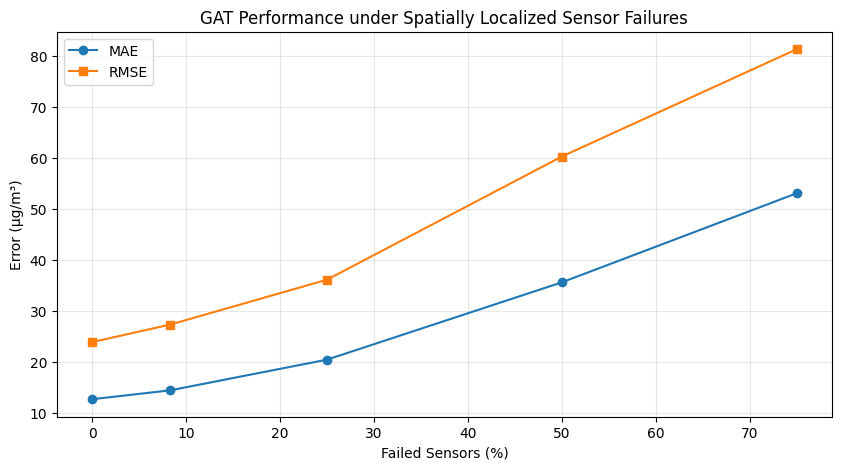

In [77]:
plt.figure(figsize=(10, 5))

plt.plot(
    gat_spatial_degradation["Failure Percentage"],
    gat_spatial_degradation["MAE"],
    marker="o",
    label="MAE"
)

plt.plot(
    gat_spatial_degradation["Failure Percentage"],
    gat_spatial_degradation["RMSE"],
    marker="s",
    label="RMSE"
)

plt.title(
    "GAT Performance under Spatially Localized Sensor Failures"
)

plt.xlabel("Failed Sensors (%)")
plt.ylabel("Error (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [78]:
gat_random_mean = (
    gat_random_results_df
    .groupby("Failure Percentage")[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

gat_spatial_mean = (
    gat_spatial_results_df
    .groupby("Failure Percentage")[["MAE", "RMSE", "R2"]]
    .mean()
    .reset_index()
)

gat_scenario_comparison = gat_random_mean.merge(
    gat_spatial_mean,
    on="Failure Percentage",
    suffixes=("_Random", "_Spatial")
)

display(gat_scenario_comparison.round(4))

,Failure Percentage,MAE_Random,RMSE_Random,R2_Random,MAE_Spatial,RMSE_Spatial,R2_Spatial
0,0.00,12.7531,23.9496,0.9332,12.7531,23.9496,0.9332
1,8.33,14.7529,27.1259,0.9139,14.4995,27.3915,0.9126
2,25.00,21.3162,36.8223,0.8408,20.5076,36.1824,0.8472
3,50.00,34.2446,53.1699,0.6694,35.6637,60.3244,0.5736
4,75.00,48.6316,71.7553,0.3972,53.1217,81.3590,0.2290


In [79]:
gat_files = {
    "GAT_Normal_Baseline.csv": pd.DataFrame([{
        "Algorithm": "GAT",
        "MAE": gat_mae,
        "RMSE": gat_rmse,
        "R2": gat_r2
    }]),
    "GAT_Random_Detail.csv": gat_random_results_df,
    "GAT_Random_Summary.csv": gat_random_degradation,
    "GAT_Spatial_Detail.csv": gat_spatial_results_df,
    "GAT_Spatial_Summary.csv": gat_spatial_degradation,
    "GAT_Random_vs_Spatial.csv": gat_scenario_comparison
}

for filename, dataframe in gat_files.items():
    dataframe.to_csv(filename, index=False)

print("Seluruh hasil eksperimen GAT berhasil disimpan!")

Seluruh hasil eksperimen GAT berhasil disimpan!


In [80]:
required_variables = [
    "graphsage_mae",
    "graphsage_rmse",
    "graphsage_r2",
    "gcn_mae",
    "gcn_rmse",
    "gcn_r2",
    "gat_mae",
    "gat_rmse",
    "gat_r2",
    "graphsage_random_summary",
    "graphsage_spatial_summary",
    "gcn_random_degradation",
    "gcn_spatial_degradation",
    "gat_random_degradation",
    "gat_spatial_degradation"
]

for var in required_variables:
    print(
        var,
        " tersedia" if var in globals() else " BELUM TERSEDIA"
    )

graphsage_mae  tersedia
graphsage_rmse  tersedia
graphsage_r2  tersedia
gcn_mae  tersedia
gcn_rmse  tersedia
gcn_r2  tersedia
gat_mae  tersedia
gat_rmse  tersedia
gat_r2  tersedia
graphsage_random_summary  tersedia
graphsage_spatial_summary  tersedia
gcn_random_degradation  tersedia
gcn_spatial_degradation  tersedia
gat_random_degradation  tersedia
gat_spatial_degradation  tersedia


# Perbandingan 3 Algoritma


In [81]:
baseline_comparison = pd.DataFrame([
    {
        "Algorithm": "GraphSAGE",
        "MAE": graphsage_mae,
        "RMSE": graphsage_rmse,
        "R2": graphsage_r2
    },
    {
        "Algorithm": "GCN",
        "MAE": gcn_mae,
        "RMSE": gcn_rmse,
        "R2": gcn_r2
    },
    {
        "Algorithm": "GAT",
        "MAE": gat_mae,
        "RMSE": gat_rmse,
        "R2": gat_r2
    }
])

display(baseline_comparison.round(4))

,Algorithm,MAE,RMSE,R2
0,GraphSAGE,11.2453,20.8470,0.9494
1,GCN,14.7327,26.3774,0.9190
2,GAT,12.7531,23.9496,0.9332


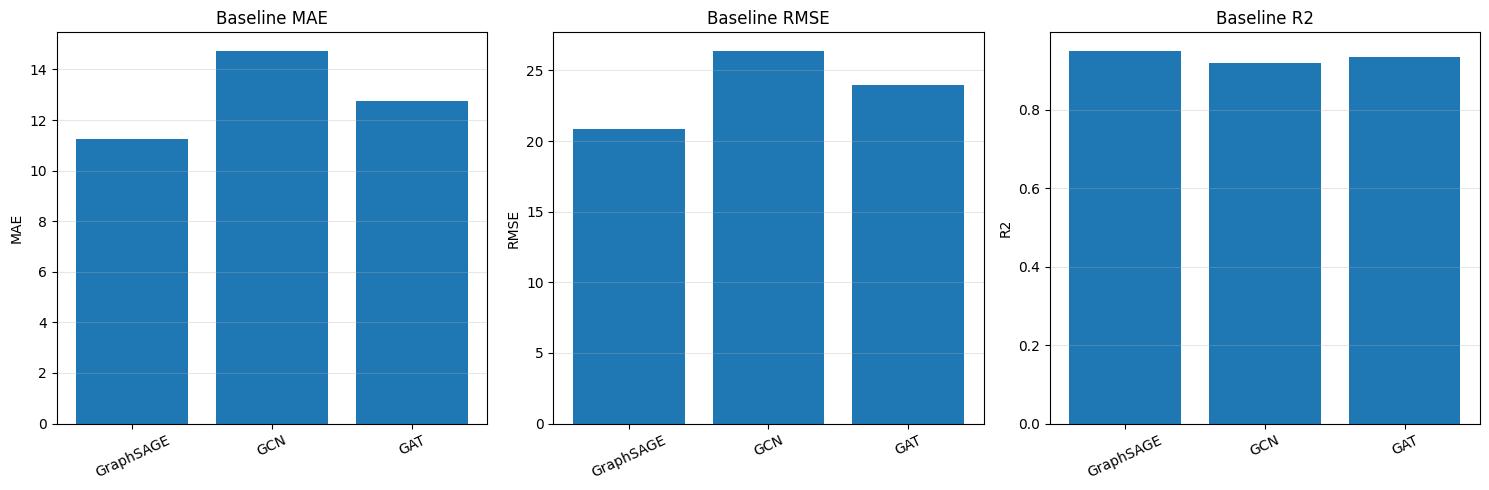

In [82]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ["MAE", "RMSE", "R2"]

for ax, metric in zip(axes, metrics):
    ax.bar(
        baseline_comparison["Algorithm"],
        baseline_comparison[metric]
    )
    ax.set_title(f"Baseline {metric}")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Perbandingan Random Sensor Failure

In [83]:
# Mengambil hasil rata-rata dari setiap algoritma
comparison_random = []

random_datasets = {
    "GraphSAGE": graphsage_random_summary,
    "GCN": gcn_random_degradation,
    "GAT": gat_random_degradation
}

for algorithm, data in random_datasets.items():

    temp = data.copy()

    # Mengambil nilai rata-rata jika tersedia dalam bentuk MultiIndex
    if isinstance(temp.columns, pd.MultiIndex):
        temp.columns = [
            col[0] if col[1] == "mean" else "_".join(
                str(x) for x in col if x
            )
            for col in temp.columns
        ]

    temp["Algorithm"] = algorithm
    comparison_random.append(temp)

random_comparison_df = pd.concat(
    comparison_random,
    ignore_index=True
)

display(
    random_comparison_df[
        [
            "Algorithm",
            "Failure Percentage",
            "MAE",
            "RMSE",
            "R2"
        ]
    ].round(4)
)

,Algorithm,Failure Percentage,MAE,RMSE,R2
0,GraphSAGE,0.00,11.2453,20.8470,0.9494
1,GraphSAGE,8.33,14.3993,27.2925,0.9131
2,GraphSAGE,25.00,21.8433,39.1837,0.8211
3,GraphSAGE,50.00,35.3252,57.5679,0.6131
4,GraphSAGE,75.00,50.5547,75.7301,0.3320
5,GCN,0.00,14.7327,26.3774,0.9190
6,GCN,8.33,15.7351,27.2453,0.9136
7,GCN,25.00,20.9142,33.2677,0.8711
8,GCN,50.00,33.3860,49.3453,0.7157
9,GCN,75.00,47.9344,68.9609,0.4459


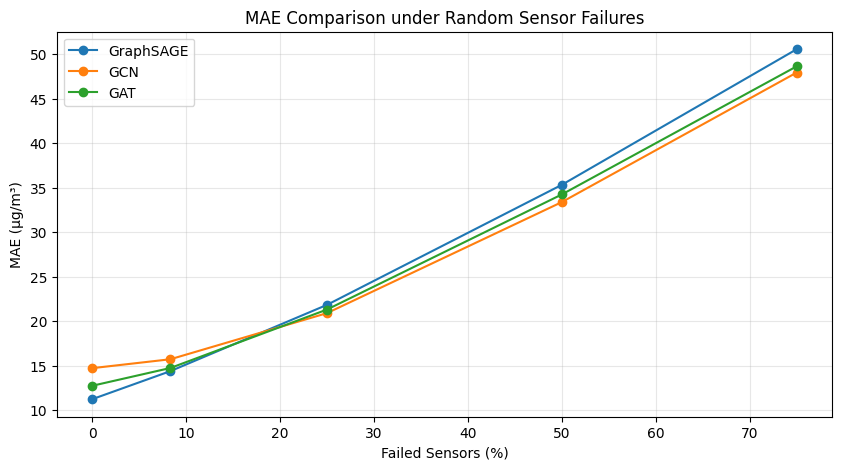

In [84]:
plt.figure(figsize=(10, 5))

for algorithm in ["GraphSAGE", "GCN", "GAT"]:

    temp = random_comparison_df[
        random_comparison_df["Algorithm"] == algorithm
    ]

    plt.plot(
        temp["Failure Percentage"],
        temp["MAE"],
        marker="o",
        label=algorithm
    )

plt.title("MAE Comparison under Random Sensor Failures")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("MAE (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Perbandingan Spatially Localized Sensor Failure

In [85]:
comparison_spatial = []

spatial_datasets = {
    "GraphSAGE": graphsage_spatial_summary,
    "GCN": gcn_spatial_degradation,
    "GAT": gat_spatial_degradation
}

for algorithm, data in spatial_datasets.items():

    temp = data.copy()

    if isinstance(temp.columns, pd.MultiIndex):
        temp.columns = [
            col[0] if col[1] == "mean" else "_".join(
                str(x) for x in col if x
            )
            for col in temp.columns
        ]

    temp["Algorithm"] = algorithm
    comparison_spatial.append(temp)

spatial_comparison_df = pd.concat(
    comparison_spatial,
    ignore_index=True
)

display(
    spatial_comparison_df[
        [
            "Algorithm",
            "Failure Percentage",
            "MAE",
            "RMSE",
            "R2"
        ]
    ].round(4)
)

,Algorithm,Failure Percentage,MAE,RMSE,R2
0,GraphSAGE,0.00,11.2453,20.8470,0.9494
1,GraphSAGE,8.33,14.4295,28.5398,0.9051
2,GraphSAGE,25.00,22.9315,43.4291,0.7799
3,GraphSAGE,50.00,37.6385,63.6749,0.5276
4,GraphSAGE,75.00,52.6032,81.1392,0.2327
5,GCN,0.00,14.7327,26.3774,0.9190
6,GCN,8.33,15.6561,27.6592,0.9109
7,GCN,25.00,21.3844,35.7511,0.8509
8,GCN,50.00,34.6890,55.0143,0.6470
9,GCN,75.00,50.0961,75.5492,0.3340


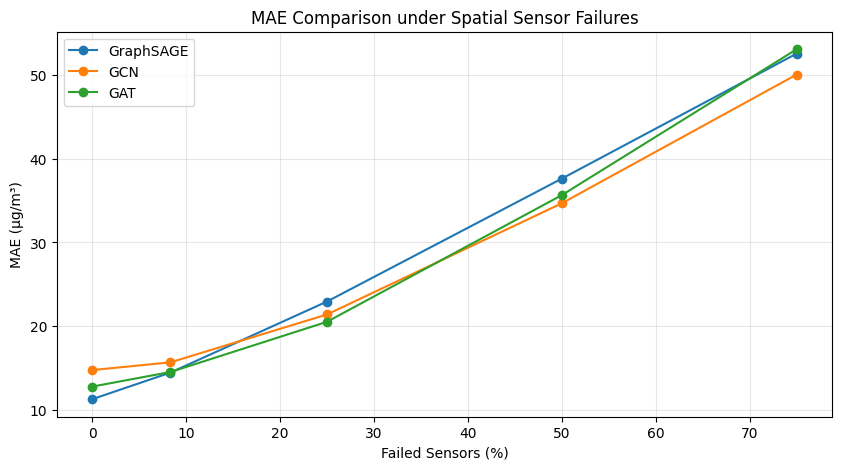

In [86]:
plt.figure(figsize=(10, 5))

for algorithm in ["GraphSAGE", "GCN", "GAT"]:

    temp = spatial_comparison_df[
        spatial_comparison_df["Algorithm"] == algorithm
    ]

    plt.plot(
        temp["Failure Percentage"],
        temp["MAE"],
        marker="o",
        label=algorithm
    )

plt.title("MAE Comparison under Spatial Sensor Failures")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("MAE (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Perbandingan Performance Degradation

In [87]:
degradation_datasets = {
    "Random": {
        "GraphSAGE": graphsage_random_summary,
        "GCN": gcn_random_degradation,
        "GAT": gat_random_degradation
    },
    "Spatial": {
        "GraphSAGE": graphsage_spatial_summary,
        "GCN": gcn_spatial_degradation,
        "GAT": gat_spatial_degradation
    }
}

for scenario, datasets in degradation_datasets.items():

    frames = []

    for algorithm, data in datasets.items():

        temp = data.copy()

        if isinstance(temp.columns, pd.MultiIndex):
            temp.columns = [
                col[0] if col[1] == "mean" else "_".join(
                    str(x) for x in col if x
                )
                for col in temp.columns
            ]

        temp["Algorithm"] = algorithm
        frames.append(temp)

    result = pd.concat(frames, ignore_index=True)

    print(f"\n=== {scenario.upper()} FAILURE DEGRADATION ===")

    display(
        result[
            [
                "Algorithm",
                "Failure Percentage",
                "MAE Degradation (%)",
                "RMSE Degradation (%)",
                "R2 Degradation (%)"
            ]
        ].round(4)
    )


=== RANDOM FAILURE DEGRADATION ===


,Algorithm,Failure Percentage,MAE Degradation (%),RMSE Degradation (%),R2 Degradation (%)
0,GraphSAGE,0.00,0.0000,0.0000,0.0000
1,GraphSAGE,8.33,28.0469,30.9179,3.8190
2,GraphSAGE,25.00,94.2427,87.9583,13.5098
3,GraphSAGE,50.00,214.1318,176.1446,35.4252
4,GraphSAGE,75.00,349.5613,263.2658,65.0302
5,GCN,0.00,0.0000,0.0000,0.0000
6,GCN,8.33,6.8035,3.2902,0.5905
7,GCN,25.00,41.9577,26.1221,5.2074
8,GCN,50.00,126.6113,87.0741,22.1246
9,GCN,75.00,225.3599,161.4393,51.4755



=== SPATIAL FAILURE DEGRADATION ===


,Algorithm,Failure Percentage,MAE Degradation (%),RMSE Degradation (%),R2 Degradation (%)
0,GraphSAGE,0.00,0.0000,0.0000,0.0000
1,GraphSAGE,8.33,28.3157,36.9011,4.6642
2,GraphSAGE,25.00,103.9198,108.3227,17.8484
3,GraphSAGE,50.00,234.7031,205.4386,44.4262
4,GraphSAGE,75.00,367.7775,289.2122,75.4910
5,GCN,0.00,0.0000,0.0000,0.0000
6,GCN,8.33,6.2675,4.8595,0.8803
7,GCN,25.00,45.1489,35.5370,7.4060
8,GCN,50.00,135.4554,108.5659,29.5955
9,GCN,75.00,240.0324,186.4163,63.6574


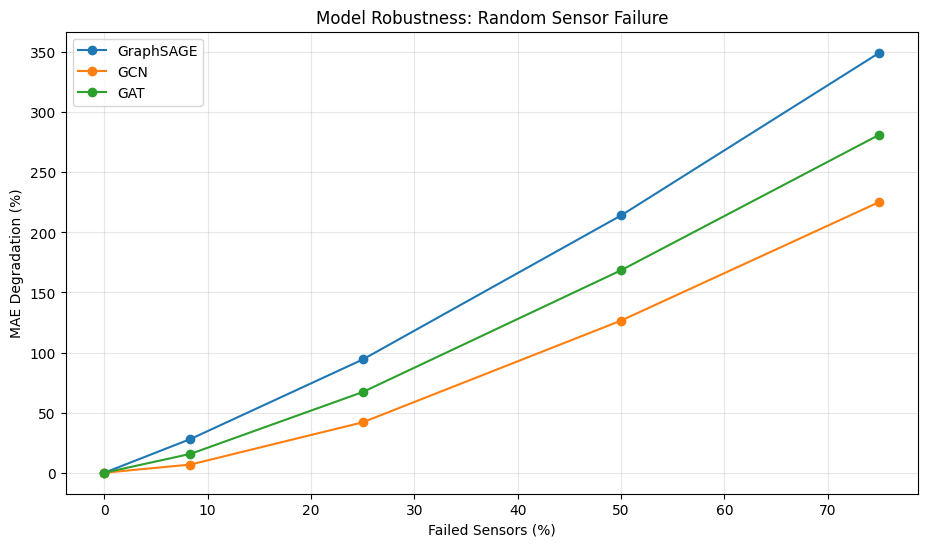

In [88]:
plt.figure(figsize=(11, 6))

for algorithm, data in degradation_datasets["Random"].items():

    plt.plot(
        data["Failure Percentage"],
        data["MAE Degradation (%)"],
        marker="o",
        label=algorithm
    )

plt.title("Model Robustness: Random Sensor Failure")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("MAE Degradation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

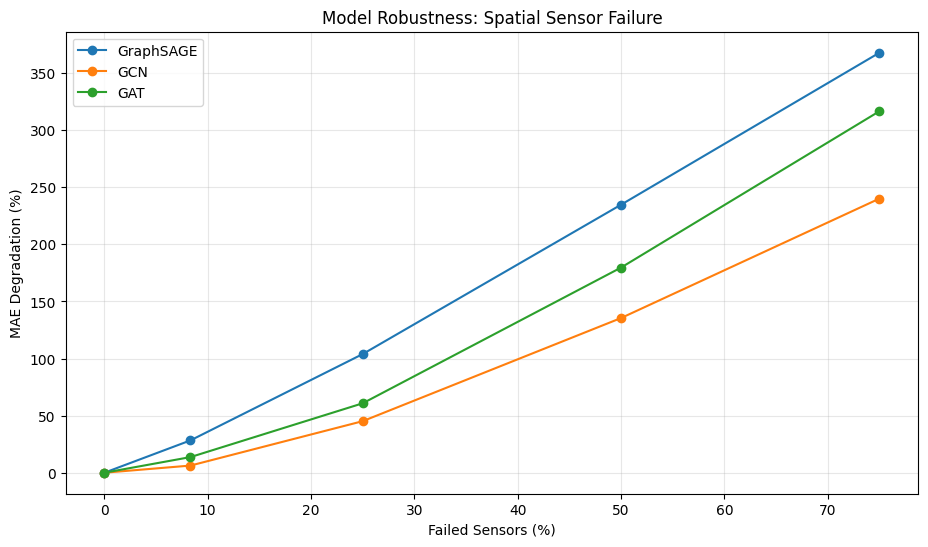

In [89]:
plt.figure(figsize=(11, 6))

for algorithm, data in degradation_datasets["Spatial"].items():

    plt.plot(
        data["Failure Percentage"],
        data["MAE Degradation (%)"],
        marker="o",
        label=algorithm
    )

plt.title("Model Robustness: Spatial Sensor Failure")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("MAE Degradation (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [90]:
baseline_comparison.to_csv(
    "Final_Baseline_Comparison.csv",
    index=False
)

random_comparison_df.to_csv(
    "Final_Random_Comparison.csv",
    index=False
)

spatial_comparison_df.to_csv(
    "Final_Spatial_Comparison.csv",
    index=False
)

print("Seluruh tabel perbandingan berhasil disimpan!")

Seluruh tabel perbandingan berhasil disimpan!


# Lanjutan perbandingan


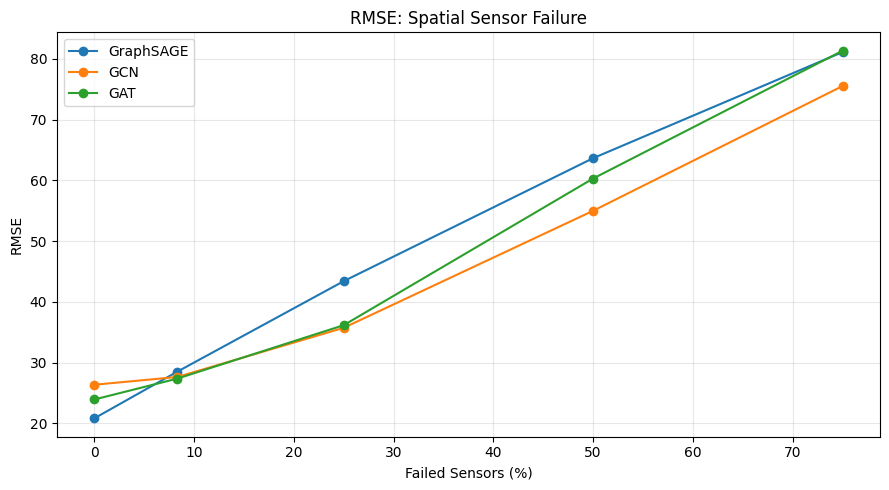

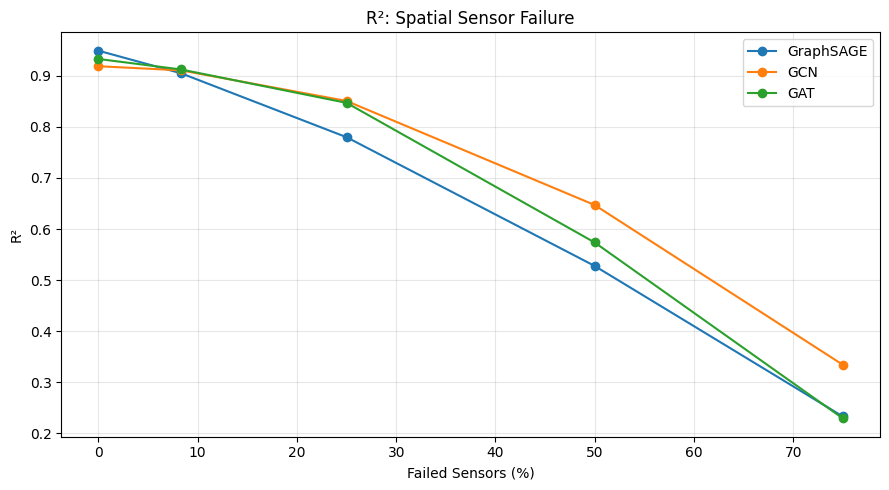

In [91]:

import pandas as pd
import matplotlib.pyplot as plt

# Data hasil spatial sensor failure
spatial_results = pd.DataFrame({
    "Failure Percentage": [0, 8.33, 25, 50, 75],
    "GraphSAGE_RMSE": [20.847, 28.5398, 43.4291, 63.6749, 81.1392],
    "GCN_RMSE": [26.3774, 27.6592, 35.7511, 55.0143, 75.5492],
    "GAT_RMSE": [23.9496, 27.3915, 36.1824, 60.3244, 81.359],
    "GraphSAGE_R2": [0.9494, 0.9051, 0.7799, 0.5276, 0.2327],
    "GCN_R2": [0.9190, 0.9109, 0.8509, 0.6470, 0.3340],
    "GAT_R2": [0.9332, 0.9126, 0.8472, 0.5736, 0.2290]
})

# Grafik RMSE
plt.figure(figsize=(9, 5))

for model in ["GraphSAGE", "GCN", "GAT"]:
    plt.plot(
        spatial_results["Failure Percentage"],
        spatial_results[f"{model}_RMSE"],
        marker="o",
        label=model
    )

plt.title("RMSE: Spatial Sensor Failure")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Grafik R2
plt.figure(figsize=(9, 5))

for model in ["GraphSAGE", "GCN", "GAT"]:
    plt.plot(
        spatial_results["Failure Percentage"],
        spatial_results[f"{model}_R2"],
        marker="o",
        label=model
    )

plt.title("R²: Spatial Sensor Failure")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("R²")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


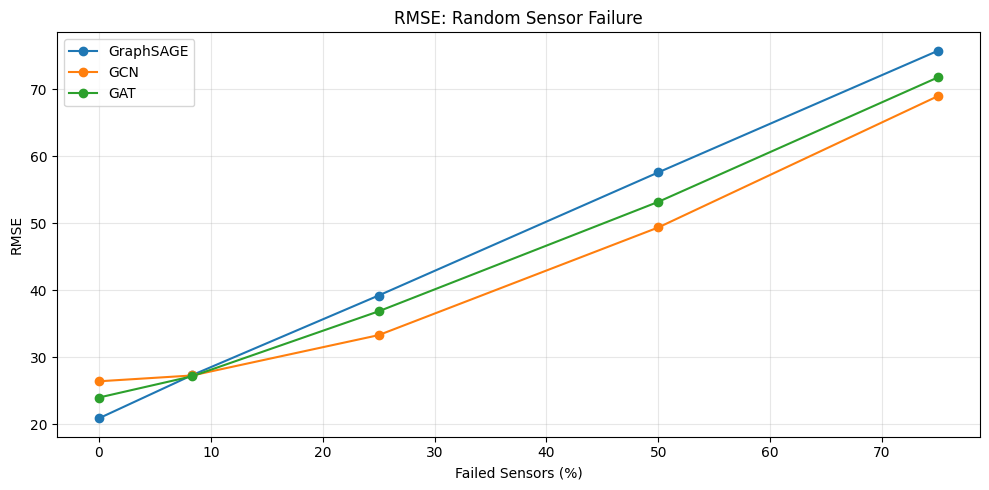

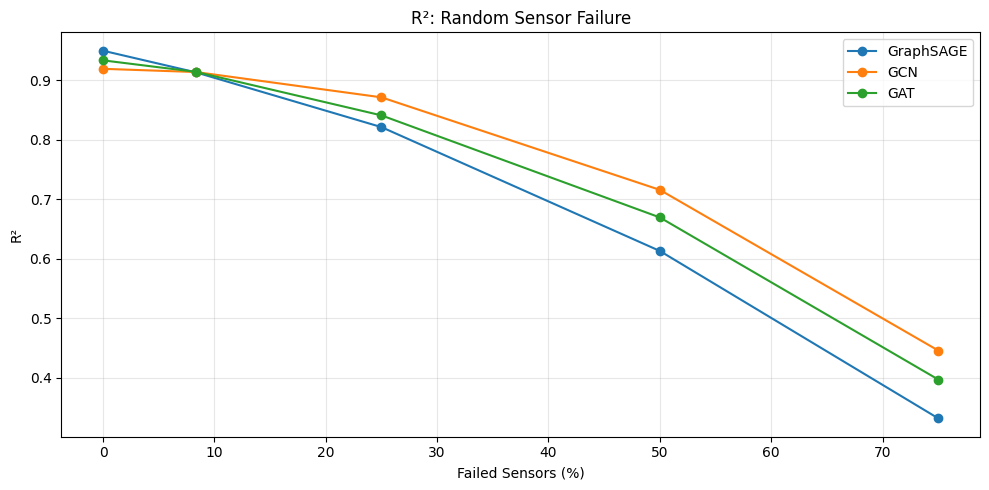

In [92]:

import pandas as pd
import matplotlib.pyplot as plt

# Data hasil eksperimen Random Sensor Failure
random_results = pd.DataFrame({
    "Failure Percentage": [0, 8.33, 25, 50, 75],
    "GraphSAGE_RMSE": [20.8470, 27.2925, 39.1837, 57.5679, 75.7301],
    "GCN_RMSE": [26.3774, 27.2453, 33.2677, 49.3453, 68.9609],
    "GAT_RMSE": [23.9496, 27.1259, 36.8223, 53.1699, 71.7553],
    "GraphSAGE_R2": [0.9494, 0.9131, 0.8211, 0.6131, 0.3320],
    "GCN_R2": [0.9190, 0.9136, 0.8711, 0.7157, 0.4459],
    "GAT_R2": [0.9332, 0.9139, 0.8408, 0.6694, 0.3972]
})

# Grafik RMSE
plt.figure(figsize=(10, 5))

for model in ["GraphSAGE", "GCN", "GAT"]:
    plt.plot(
        random_results["Failure Percentage"],
        random_results[f"{model}_RMSE"],
        marker="o",
        label=model
    )

plt.title("RMSE: Random Sensor Failure")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Grafik R2
plt.figure(figsize=(10, 5))

for model in ["GraphSAGE", "GCN", "GAT"]:
    plt.plot(
        random_results["Failure Percentage"],
        random_results[f"{model}_R2"],
        marker="o",
        label=model
    )

plt.title("R²: Random Sensor Failure")
plt.xlabel("Failed Sensors (%)")
plt.ylabel("R²")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
